## **Distributed Lag Non-Linear Model**

In [61]:
# Import necessary libraries

# Basics
import itertools
import warnings
from IPython.display import display, Markdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# DLNM helpers 
from pydlnm.basis import CrossBasis
from pydlnm.prediction import crosspred
from dlnm import plot_crosspred, cb_pen

# statsmodels for GLMGam
import statsmodels.api as sm
from statsmodels.gam.api import GLMGam
from statsmodels.gam.smooth_basis import UnivariateBSplines, UnivariateCubicCyclicSplines, GenericSmoothers
from statsmodels.tsa.stattools import acf

# Zero-Inflated Negative Binomial
import pymc as pm
import arviz as az
import pytensor.tensor as pt

---
#### Negative Binmoial Setting Functions

##### Construction

In [62]:
# CrossBasis matrix construction
def cb_construct(dataframe, col_lst, max_lag, setting_lst):
    # Input the processed data, exposure variable list, maximum lag value, and the CrossBasis setting list
    var_degree, var_df, lag_degree, lag_df = setting_lst
    b_knots = np.percentile(df["temprange"], [5, 95])

    # Construct the CrossBasis matrix for every single exposure variable in the exposure variable list, and store them in cb_list
    cb_list = []
    for col in col_lst:        
        # Uses natural spline instead of bs
        cb = CrossBasis(
                    dataframe[col].values, lag=max_lag,
                    argvar={"fun": "ns", "df": var_df},
                    arglag={"fun": "ns", "df": lag_df}
                )
        cb_list.append(cb)

    # Construct the final CrossBasis matrix
    X_exposure = np.concatenate([np.asarray(cb) for cb in cb_list], axis=1)
    n_basis_per_exp = X_exposure.shape[1] // len(col_lst)
    exp_name_list = [f"{col}_basis_{i}" for col in col_lst for i in range(n_basis_per_exp)]

    base = dataframe.reset_index(drop=True).iloc[max_lag:].copy()
    basis_df = pd.DataFrame(X_exposure[max_lag:], columns=exp_name_list, index=base.index)
    model_data = pd.concat([base, basis_df], axis=1)

    # Return the final CrossBasis matrix, exposure variable name list, CrossBasis matrix list
    return model_data, exp_name_list, cb_list

In [63]:
# Smoothers construction
def smoother_construct(dataframe, bs_dict, ccs_dict):
    # Input the CrossBasis matrix, dictionary for BSpline setting, diction for Cyclic Cubic Splines setting 

    # Construct a single BSpline with each of the setting in bs_dict
    # bs_dict follows the format: [name, df, degree]
    bs_list = []
    for i, name in enumerate(bs_dict["name"]):
        bs = UnivariateBSplines(dataframe[name].values, df=bs_dict["df"][i], degree=bs_dict["degree"][i], variable_name=name, include_intercept=False)
        bs_list.append(bs)

    # Construct a single Cyclic Cubic Spline with each of the setting in ccs_dict
    # ccs_dict follows the format: [name, df]
    # remark: for Cyclic Cublic Spline, the degree must be 3
    ccs_list = []
    for i, name in enumerate(ccs_dict["name"]):
        ccs = UnivariateCubicCyclicSplines(dataframe[name].values, df=ccs_dict["df"][i], variable_name=name, constraints="center")
        ccs_list.append(ccs)

    # Combine all the Splines together
    sm_weights = bs_list + ccs_list
    smooth_names = list(bs_dict["name"]) + list(ccs_dict["name"])
    X_smooth = dataframe[smooth_names]

    # Return the combined smoother term 
    return GenericSmoothers(X_smooth, sm_weights)

In [64]:
# DLNM model construction with Negative Binomial
def model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_para):
    # Input the CrossBasis matrix, target variable, exposure variable list, linear predictor list, constructed smoothers, alpha values list, dispersion parameter value

    # Form the formula needed for the function GLMGam()
    terms = list(exp_names) + list(linear_predictors)
    formula = f"{tar_var} ~ {' + '.join(terms)}"

    # Turn the alpha values list to numpy.array
    alpha = np.asarray(alpha, dtype=float)

    # Construct the model with the formula and smoothers, with Negative Binomial distribution and an offset of logged population value
    model = GLMGam.from_formula(formula, data=dataframe, smoother=smoothers, alpha=alpha, family=sm.families.NegativeBinomial(alpha=disp_para), offset=dataframe["Log_population"].to_numpy(dtype=float))

    # Fit the model to get the result
    result = model.fit()

    # Return the model and the result
    return model, result

##### Hyperparameter tuning

In [65]:
# CrossBasis matrix degree and degrees of freedom (df) tuning 
def cb_tune(dataframe, tar_var, exp_col, linear_predictors, bs_dict, ccs_dict, alpha, disp_para, max_lag, grid):
    # Input the processed data, target variable, exposure column list, linear predictor list, 
    #           dictionary of the initial settings for BSpline, dictionary of the initial seetings for Cyclic Cubic Splines, 
    #           the initial alpha value, the initial dispersion parameter value, maximum lag, and the testing grid

    print(f"{'='*30} Tuning CrossBasis settings {'='*30}")
    best_idx = 0
    performance = []

    # Every options in grid follows the following format 
    # [degree in exposure dimension, df in exposure dimension, degree in lag dimension, df in lag dimension]
    for option in grid:
        # Construct the initial CrossBasis and smoothers
        model_data, exp_names, _ = cb_construct(dataframe, exp_col, max_lag, option)
        smoothers = smoother_construct(model_data, bs_dict, ccs_dict)

        # Construct the model with every combination of options and evaluate the performance with BIC value
        try:
            _, result = model_construct(model_data, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_para)
            bic = result.bic
        except Exception as e:
            print(f"option {option} failed: {e}")
            bic = np.inf
        performance.append(bic)
        print(f"BIC for {option}: {bic:.2f}" if np.isfinite(bic) else f"BIC for {option}: failed")

    # Find the setting with the best performance (lowest BIC value)
    for i in range(1, len(performance)):
        if performance[i] < performance[best_idx]:
            best_idx = i

    best_setting = grid[best_idx]
    print(f"Best CrossBasis setting: {best_setting} (BIC = {performance[best_idx]:.2f})")

    # Return the CrossBasis constructed with the best setting
    return cb_construct(dataframe, exp_col, max_lag, best_setting)

In [66]:
# Function for tuning the degrees of freedom of each smoother terms 
def smoother_tune(dataframe, tar_var, exp_names, linear_predictors, alpha, disp_para, bs_name_lst, ccs_name_lst, grid):
    # Input the CrossBasis matrix, target variable, expposure variable list, linear predictor list, initial alpha value, initial dispersion parameter value
    #           the variable name list for BSpline, the variable name list for Cyclic Cubic Splines, and the testing grid

    print(f"\n{'='*30} Tuning smoother degrees of freedom {'='*30}")
    n_bs = len(bs_name_lst)
    best_idx = 0
    performance = []

    # Every options in the grid follow the following format
    # [df for B Spline, df for Cyclic Cubic Spline 1, df for Cyclic Cubic Spline 2]
    for option in grid:
        # Construct the dictionary to fit in the function smoother_construct()
        bs_dfs = list(option[:n_bs])
        ccs_dfs = list(option[n_bs:])
        bs_dict = {"name": bs_name_lst, "degree": [3] * n_bs, "df": bs_dfs}
        ccs_dict = {"name": ccs_name_lst, "df": ccs_dfs}

        smoothers = smoother_construct(dataframe, bs_dict, ccs_dict)

        # Construct the model with every combination of settings and evaluate the performance with BIC value (with sum of Effective Degrees of Freedom EDF value)
        try:
            _, result = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_para)
            bic = result.bic
            edf = float(np.sum(result.edf))
        except Exception as e:
            print(f"option {option} failed: {e}")
            bic, edf = np.inf, np.nan

        performance.append((bic, edf))
        print(f"Degrees of freedom {option}: BIC={bic:.4f} | sum(EDF)={edf:.4f}")

    # Find the setting with the best performance (with lowest BIC value)
    for i in range(1, len(performance)):
        if performance[i][0] < performance[best_idx][0]:
            best_idx = i

    best_option = grid[best_idx]
    print(f"Best smoother setting: {best_option} (BIC={performance[best_idx][0]:.4f})")

    bs_dict = {"name": bs_name_lst, "degree": [3] * n_bs, "df": list(best_option[:n_bs])}
    ccs_dict = {"name": ccs_name_lst, "df": list(best_option[n_bs:])}

    # Return the smoothers constructed with the best setting
    return smoother_construct(dataframe, bs_dict, ccs_dict)

In [67]:
# Alpha value tuning
def alpha_tune(dataframe, tar_var, exp_names, linear_predictors, smoothers, start_alpha, disp_para, criterion_lst=["bic", "gcv"], method="nm"):
    # Input the CrossBasis matrix, target variable, exposure variable list, linear predictor list, optimizied smoothers, the starting alpha value, 
    #           initial dispersion parameter value, list of criterion used to tune alpha (default: bic and gcv), and the method (default: nm)

    print(f"\n{'='*30} Tuning smoother weights (α) {'='*30}")
    start_alpha = np.asarray(start_alpha, dtype=float)
    model, _ = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, start_alpha, disp_para)

    # Find the optimized alpha value with each criterion in the criterion_lst
    alpha_out_lst = []
    for criterion in criterion_lst:
        best_alpha = model.select_penweight(criterion=criterion, method=method, start_params=start_alpha)
        if isinstance(best_alpha, (list, tuple)):
            candidate = best_alpha[0]
            alpha_out = np.asarray(candidate if np.ndim(candidate) > 0 else best_alpha, dtype=float)
        else:
            alpha_out = np.asarray(best_alpha, dtype=float).ravel()
        alpha_out_lst.append(alpha_out)
        print(f"Best alpha found with {criterion}: {alpha_out}")

    # ensure derivative bases exist
    for s in smoothers.smoothers:
        if getattr(s, "der_basis", None) is None:
            s.der_basis = np.zeros_like(s.basis)
        if getattr(s, "der2_basis", None) is None:
            s.der2_basis = np.zeros_like(s.basis)

    # Find the optimized alpha value with KFold
    try:
        best_a_kfold = model.select_penweight_kfold()
        alpha_out_lst.append(best_a_kfold[0])
        print(f"Best alpha found with Kfold: {best_a_kfold[0]}")
    except Exception as e:
        print(f"Kfold alpha selection failed: {e}")
        alpha_out_lst.append(alpha_out_lst[0])

    # Comparison table for the optimized alpha value found with different criterions (including AIB, BIC, GCV, and EDF value)
    results = {}
    for name, a in zip(criterion_lst+["KFold"], alpha_out_lst):
        try:
            _, res = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, a, disp_para)
            results[name] = {"alpha": a, "AIC": res.aic, "BIC": res.bic, "GCV": getattr(res, "gcv", np.nan), "EDF": res.edf.sum()}
        except Exception:
            results[name] = {"alpha": a, "AIC": np.nan, "BIC": np.nan, "GCV": np.nan, "EDF": np.nan}

    print("Alpha values comparison:")
    display(pd.DataFrame(results).T)

    # Return KFold selected alpha
    return alpha_out_lst[-1]  

In [68]:
# Dispersion parameter value tuning 
def disp_tune(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_grid):
    # Input the CrossBasis matrix, target variable, exposure variable list, linear predictor list, optimized smoothers, optimized alpha value, and the testing grid

    print(f"\n{'='*30} Tuning Negative Binomial dispersion parameter {'='*30}")
    performance = []

    # Evaluate the model performance with each dispersion parameter value in the grid with the Pearson ratio value (Pearson chi2 / residual) and BIC
    for disp in disp_grid:
        try:
            _, result = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp)
            pearson_ratio = result.pearson_chi2 / result.df_resid
            performance.append((disp, pearson_ratio, result.bic))
            print(f"Dispersion {disp:5.1f}: Pearson ratio = {pearson_ratio:.4f} | BIC = {result.bic:.4f}")
        except Exception as e:
            print(f"Dispersion {disp} failed: {e}")

    if not performance:
        raise RuntimeError("All dispersion values failed.")

    # Return the optimized dispersion parameter value with the best performance (lowest difference of the Pearson ratio with 1.0)
    best = min(performance, key=lambda x: abs(x[1] - 1.0))
    print(f"\nBest dispersion parameter: {best[0]} (Pearson ratio = {best[1]:.4f})")
    return best[0]

##### Result Diagnostics (model performance)

In [69]:
# Model metrics for DLNM with Negative Binomial
def model_metric(result):
    # Input the result of DLNM

    # Print the values of AIC, BIC, Deviance, Pearson Chi2, scale, EDF, Sum of EDF 
    print(f"AIC: {result.aic}")
    print(f"BIC: {result.bic}")
    print(f"Deviance: {result.deviance}")
    print(f"Pearson Chi2: {result.pearson_chi2}")
    print(f"Scale/Dispersion: {result.scale}")
    print(f"Effective degree of freedom: \n{result.edf}")
    print(f"Total EDF: {result.edf.sum()}")

In [70]:
# Residual diagnostics (graph plots) for DLNM with Negative Binomial
def residual_diagnostics(result):
    # Extract the residual deviance
    residuals = result.resid_deviance

    fig, axes = plt.subplots(1, 2, figsize=(15, 4))
    # 1. Residuals vs. Fitted Values Plot 
    # checks for systematic bias
    axes[0].scatter(result.fittedvalues, residuals, alpha=0.3)
    axes[0].axhline(0, color='red', linestyle='--')
    axes[0].set_xlabel("Fitted Values")
    axes[0].set_ylabel("Deviance Residuals")
    axes[0].set_title("Residuals vs Fitted")

    # 2. Autocorrelation Check (ACF) 
    # residuals should look like white noise.
    sm.graphics.tsa.plot_acf(residuals, lags=10, ax=axes[1])
    axes[1].set_xlabel("Lag (Week)")
    axes[1].set_title("Autocorrelation of Residuals (ACF)")

    plt.tight_layout()
    plt.show()

#### Zero-Inflated Negative Binomial

##### Preparation

In [71]:
# Extract from the constructed smoothers
def extract_smoother_bases(smoothers):
    # Input the constructed smoothers in Negative Binomial part

    bases = []
    for s in smoothers.smoothers:
        name = getattr(s, "variable_name", "smooth")
        # statsmodels Univariate* objects store the evaluated basis in .basis
        B = np.asarray(s.basis)
        bases.append((name, B))

    # Return the smoother bases
    return bases


In [72]:
# Extract the independent variable values and names from what is set in Negative Binomial
def build_full_design_matrix(model_data, exp_name_list, linear_predictors_list, smoothers):
    # Input the constructed data for Negative Binomial DLNM, exposure name list, linear predictor name list, and smoothers

    parts = []
    col_names = []

    # ----- Cross-basis columns ------------------------------------------------------------------------------
    X_cb = model_data[exp_name_list].values
    parts.append(X_cb)
    col_names.extend(exp_name_list)

    # ----- Linear predictors ------------------------------------------------------------------------------
    X_lin = model_data[linear_predictors_list].values
    parts.append(X_lin)
    col_names.extend(linear_predictors_list)

    # ----- Smoother bases ------------------------------------------------------------------------------
    for name, B in extract_smoother_bases(smoothers):
        parts.append(B)
        col_names.extend([f"{name}_s{i}" for i in range(B.shape[1])])

    X = np.column_stack(parts)
    # drop any constant / all-zero columns that can appear after lag truncation
    keep = np.std(X, axis=0) > 1e-12

    # Retrieve the final version of X and the corresponding names and return them 
    X = X[:, keep]
    col_names = [c for c, k in zip(col_names, keep) if k]
    return X, col_names

In [73]:

def build_separated_design_matrices(
        model_data, exp_name_list, linear_predictors_list, smoothers, 
        psi_predictors, 
        history_var=None
        ):
    # Input the constructed dataframe for Negative Binomial DLNM, exposure name list, linear predictors name list, and smoothers for the construction of full design matrix function
    # Input the name list with variables that may affect the distribution of zeros
    # Input the variable name containing history of target variable (if any) (usualy from linear predictors)
    
    # -----  Full matrix for the mean component -------------------------------------------------------------------
    # Retreive the X mean and the corresponding column names
    X_mu, colnames_mu = build_full_design_matrix(model_data, exp_name_list, linear_predictors_list, smoothers)
    X_mu = np.column_stack([np.ones(X_mu.shape[0]), X_mu])
    colnames_mu = ["intercept_mu"] + list(colnames_mu)

    # ----- Target variable history predictor ------------------------------
    if history_var is not None:
        # Get the mean, standard deviation for the previous value of the target variable, and standarlize it 
        X_history = model_data[[history_var]].to_numpy(dtype=float)
        history_mean = X_history.mean(axis=0)
        history_sd = X_history.std(axis=0)
        X_history_std = (X_history - history_mean) / history_sd

        # Append the new values to X_mu, and colnames_mu
        X_mu = np.column_stack([X_mu, X_history_std])
        colnames_mu = list(colnames_mu) + [history_var]

    # -----  Simple matrix for psi ---------------------------------------------------------------------------------
    # Retreive the psi predictor values with intercept of 1s and the corresponding column names
    X_psi = model_data[psi_predictors].values.astype(float)
    X_psi = np.column_stack([np.ones(len(X_psi)), X_psi])
    colnames_psi = ["intercept_psi"] + list(psi_predictors)

    # Return 
    return X_mu, colnames_mu, X_psi, colnames_psi

##### Construction 

In [74]:
# Model construction with Zero-Inflated Negative Binomial
def model_construct_zinb_separated(
        model_data, tar_var, X_mu, colnames_mu, X_psi=None, colnames_psi=None, log_pop=None, 
        prior_sigma=0.5, draws=2000, tune=2000, target_accept=0.97, cores=4, chains=4, random_seed=42, 
        zero_model="constant"
        ):

    y = model_data[tar_var].values.astype(float)
    n_obs = len(y)

    # Check data
    if not np.isfinite(y).all() or np.any(y < 0):
        raise ValueError("Invalid outcome values.")
    if not np.isfinite(X_mu).all():
        raise ValueError("X_mu contains NaN or Inf.")
    if not np.isfinite(log_pop).all():
        raise ValueError("Invalid population offset.")

    # Separate intercept from other predictors
    X_mu = np.asarray(X_mu, dtype=float)

    # Assume first column is the intercept of 1s
    X_mu_reg = X_mu[:, 1:]

    coords = {"coef_mu": list(colnames_mu[1:]), "obs": np.arange(n_obs)}

    with pm.Model(coords=coords) as model:
        X_data = pm.Data("X_mu", X_mu_reg, dims=("obs", "coef_mu"))
        log_pop_data = pm.Data("log_pop", log_pop, dims="obs")
        y_data = pm.Data("y", y, dims="obs")

        # -------- Mean parameter --------------------------------------------------------------------------------------------
        intercept_mu = pm.Normal("intercept_mu", mu=0, sigma=2)
        beta = pm.Normal("beta", mu=0, sigma=prior_sigma, dims="coef_mu")

        # log_mu = beta_0+beta_1*X_1+...+log(offset)
        eta_mu = (intercept_mu + pm.math.dot(X_data, beta) + log_pop_data)
        # mu = exp(log_mu)
        mu = pm.Deterministic("mu", pm.math.exp(eta_mu), dims="obs")

        # -------- Zero-inflation parameter -----------------------------------------------------------------------------------
        # Assumes constant zero inflation
        if zero_model == "constant":
            # psi is the probability the observation belongs to the always zero group
            # Bayesian prior
            psi = pm.Beta("psi", alpha=2, beta=2)

        # Not constant zero inflation and use inverse logit function for the bayesian prior
        elif zero_model == "regression":
            X_psi_data = pm.Data("X_psi", X_psi, dims=("obs", "coef_psi"))
            gamma = pm.Normal("gamma", mu=0, sigma=1, dims="coef_psi")

            psi = pm.Deterministic("psi", pm.math.invlogit(pm.math.dot(X_psi_data, gamma)), dims="obs")
        else:
            raise ValueError("Unknown zero_model.")

        # -------- NB dispersion parameter ------------------------------------------------------------------------------------
        # why use log normal -> alpha must be positive
        alpha = pm.LogNormal("alpha", mu=np.log(5.0), sigma=0.5)

        # ------- Likelihood -------------------------------------------------------------------------------------------
        pm.ZeroInflatedNegativeBinomial("y_obs", psi=psi, mu=mu, alpha=alpha, observed=y_data, dims="obs")

        idata = pm.sample(draws=draws, tune=tune, chains=chains, cores=cores, target_accept=target_accept, init="jitter+adapt_diag", random_seed=random_seed, return_inferencedata=True, progressbar=True)
        idata = pm.compute_log_likelihood(idata, model=model)

    return model, idata, X_mu, colnames_mu


##### Result diagnostics (Model performance)

In [75]:
# Retrieve normalized group names from Inference Data
def posterior_group_names(idata):
    # retrive the groups from idata
    groups = getattr(idata, "groups", None)
    # Error Handling
    if groups is None:
        raise TypeError(f"{type(idata).__name__} does not expose a groups interface.")

    groups = groups() if callable(groups) else groups

    # Return the dictionary of the group names
    return {str(name).strip("/") for name in groups if str(name).strip("/")}

In [76]:
def residual_diagnostics_zinb(idata, model_data, tar_var, X_mu, colnames_mu, log_pop=None, max_acf_lags=10, report=None):
    y = model_data[tar_var].values.astype(float)

    if report is None:
        raise ValueError("Pass the output of zinb_performance() as report.")

    mean_hat = np.asarray(report["fitted_mean"], dtype=float)
    resid = np.asarray(report["pearson_residuals"], dtype=float)

    if mean_hat.shape != y.shape or resid.shape != y.shape:
        raise ValueError("Report and model_data must refer to the same observations.")

    psi = (
        idata.posterior["psi"].mean().item()
        if "psi" in idata.posterior else 1.0
    )

    # ---------- Plots ----------
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # 1. Residuals vs Fitted
    axes[0].scatter(mean_hat, resid, alpha=0.35, s=12, edgecolors="none")
    axes[0].axhline(0, color="red", ls="--", lw=1)
    axes[0].set_xlabel("Fitted values (E[Y])")
    axes[0].set_ylabel("Pearson residuals")
    axes[0].set_title("Residuals vs Fitted (ZINB)")

    # 2. ACF of residuals
    sm.graphics.tsa.plot_acf(resid, lags=max_acf_lags, ax=axes[1], title="ACF of Pearson residuals")
    axes[1].set_xlabel("Lag")

    # 3. Histogram of residuals
    axes[2].hist(resid, bins=40, density=True, alpha=0.7, edgecolor="white")
    axes[2].axvline(0, color="red", ls="--", lw=1)
    axes[2].set_xlabel("Pearson residual")
    axes[2].set_ylabel("Density")
    axes[2].set_title("Residual distribution")

    plt.tight_layout()
    plt.show()

    # quick numeric summary
    print(f"Pearson residual mean   : {resid.mean():.4f}")
    print(f"Pearson residual std    : {resid.std():.4f}")
    print(f"Proportion of zeros in y: {(y == 0).mean():.3f}")
    print(f"Posterior mean psi      : {np.mean(psi):.3f}")

    return resid, mean_hat


In [77]:
# Trace plot for the parameters of Zero Inflated Negative Binomial
def trace_plot_zinb(idata):
    # used parameter name list
    var_names = [v for v in ["psi", "intercept_mu", "beta", "alpha", "gamma"] if v in idata.posterior]

    # grph plot
    pc = az.plot_trace_dist(idata, var_names=var_names, compact=True)

    pc.add_legend("chain", title="Sampling chains")
    plt.tight_layout()
    plt.show()

In [78]:
def zinb_performance(idata, max_acf_lag=10, predictive_draws=1000, random_seed=42):

    required = ["X_mu", "log_pop", "y"]
    missing = [name for name in required if name not in idata.constant_data]
    if missing:
        raise ValueError(f"Missing constant_data variables: {missing}")

    y = np.asarray(idata.constant_data["y"], dtype=float)
    X = np.asarray(idata.constant_data["X_mu"], dtype=float)
    offset = np.asarray(idata.constant_data["log_pop"], dtype=float)

    if len(y) < 3:
        raise ValueError("At least three observations are required.")

    beta = (idata.posterior["beta"].stack(sample=("chain", "draw")).transpose("sample", "coef_mu").values)
    alpha = (idata.posterior["alpha"].stack(sample=("chain", "draw")).transpose("sample").values[:, None])
    psi_da = idata.posterior["psi"].stack(sample=("chain", "draw"))
    if "obs" in psi_da.dims:
        psi = psi_da.transpose("sample", "obs").values
    else:
        psi = psi_da.transpose("sample").values[:, None]

    eta = beta @ X.T + offset[None, :]
    with np.errstate(over="raise", invalid="raise"):
        mu = np.exp(eta)
        mean_draw = psi * mu
        var_draw = (psi * mu + psi * mu**2 / alpha + psi * (1.0 - psi) * mu**2)

    if not np.isfinite(var_draw).all():
        raise ValueError("Non-finite predictive variance; inspect extreme draws.")

    fitted_mean = mean_draw.mean(axis=0)
    conditional_var = var_draw.mean(axis=0)
    predictive_var = conditional_var + mean_draw.var(axis=0)

    pearson = ((y - fitted_mean) / np.sqrt(np.maximum(conditional_var, 1e-12)))
    predictive_resid = ((y - fitted_mean) / np.sqrt(np.maximum(predictive_var, 1e-12)))

    log_nb_p0 = -alpha * np.log1p(mu / alpha)
    zero_probability = (
        (1.0 - psi) + psi * np.exp(log_nb_p0)
    ).mean(axis=0)

    rng = np.random.default_rng(random_seed)
    n_sim = min(int(predictive_draws), len(beta))
    if n_sim < 2:
        raise ValueError("predictive_draws must be at least 2.")

    chosen = rng.choice(len(beta), size=n_sim, replace=False)
    a = alpha[chosen]
    m = mu[chosen]
    p = a / (a + m)

    if np.any(p <= 0) or np.any(p > 1):
        raise ValueError("Invalid NB probability; inspect posterior.")

    y_rep = rng.negative_binomial(a, p)
    y_rep *= rng.random(y_rep.shape) < psi[chosen]

    q10, q90 = np.quantile(y_rep, [0.10, 0.90], axis=0)
    q025, q975 = np.quantile(y_rep, [0.025, 0.975], axis=0)
    fitted_median = np.median(y_rep, axis=0)

    metrics = pd.Series({
        "n_observations": len(y),
        "MAE_predictive_median": np.mean(np.abs(y - fitted_median)),
        "RMSE_predictive_mean": np.sqrt(np.mean((y - fitted_mean)**2)),
        "mean_prediction_minus_observed": np.mean(fitted_mean - y),
        "observed_zero_fraction": np.mean(y == 0),
        "predicted_zero_fraction": zero_probability.mean(),
        "zero_event_Brier_score": np.mean(((y == 0).astype(float) - zero_probability)**2),
        "coverage_80": np.mean((y >= q10) & (y <= q90)),
        "coverage_95": np.mean((y >= q025) & (y <= q975)),
        "mean_interval_width_80": np.mean(q90 - q10),
        "mean_interval_width_95": np.mean(q975 - q025),
        "Pearson_residual_mean": pearson.mean(),
        "Pearson_residual_SD": pearson.std(),
        "predictive_residual_SD": predictive_resid.std(),
    }, name="in_sample_value")

    var_names = [v for v in ["beta", "gamma", "alpha"] if v in idata.posterior]
    print(f"{'='*30} PyMC ZINB posterior summary (selected parameters) {'='*30}")
    diagnostics = az.summary(idata, var_names=var_names, kind="diagnostics")
    pc = az.plot_trace_dist(idata, var_names=var_names, compact=True)
    
    pc.add_legend("chain", title="Sampling chains")
    plt.tight_layout()
    plt.show()
    display(diagnostics)

    lag_limit = min(int(max_acf_lag), len(y) - 1)
    if np.std(pearson) > 0:
        residual_acf = pd.Series(
            acf(pearson, nlags=lag_limit, fft=False)[1:],
            index=np.arange(1, lag_limit + 1),
            name="Pearson_residual_ACF",
        )
    else:
        residual_acf = pd.Series(dtype=float)

    divergences = None
    if (
        hasattr(idata, "sample_stats")
        and "diverging" in idata.sample_stats
    ):
        divergences = int(idata.sample_stats["diverging"].sum().item())

    sampling = {"divergences": divergences}
    for column, label, operation in [
        ("r_hat", "max_r_hat", "max"),
        ("ess_bulk", "min_bulk_ESS", "min"),
        ("ess_tail", "min_tail_ESS", "min"),
    ]:
        if column in diagnostics:
            values = diagnostics[column]
            sampling[label] = (
                values.max() if operation == "max"
                else values.min()
            )

    loo_result = None
    if not hasattr(az, "loo"):
        loo_status = "Installed ArviZ has no top-level loo API."
    elif "log_likelihood" not in posterior_group_names(idata):
        loo_status = "Missing log_likelihood: compute it with the fitted model."
    else:
        loo_result = az.loo(idata, pointwise=True)
        loo_status = "Computed; inspect Pareto-k diagnostics. \nThis is not leave-future-out validation."

    print("Model Metrics")
    display(metrics.to_frame())
    display(pd.Series(sampling, name="value").to_frame())
    print(loo_status)
    if loo_result is not None:
        display(loo_result)

    return {
        "metrics": metrics.to_frame(),
        "sampling": sampling,
        "parameter_diagnostics": diagnostics,
        "residual_acf": residual_acf.to_frame().T,
        "fitted_mean": fitted_mean,
        "pearson_residuals": pearson,
        "predictive_residuals": predictive_resid,
        "zero_probability": zero_probability,
        "posterior_predictive_draws": y_rep,
        "loo": loo_result
    }

#### Final result for both

In [79]:
def extract_cb_coef_from_idata(idata, colnames, exp_name, return_vcov=True, coef_dim="coef_mu"):
    basis_names = [n for n in colnames if n.startswith(f"{exp_name}_basis_")]
    if not basis_names:
        raise ValueError(f"No basis coefficients found for exposure '{exp_name}'.")

    # posterior samples of beta: (chain, draw, coef)
    beta_samples = idata.posterior["beta"].sel({coef_dim: basis_names}).values    # flatten chains
    beta_flat = beta_samples.reshape(-1, len(basis_names))

    coef_mean = beta_flat.mean(axis=0)
    if return_vcov:
        vcov = np.cov(beta_flat, rowvar=False)
        return coef_mean, vcov, basis_names
    return coef_mean, None, basis_names

In [80]:
def pred_cal(result_or_idata, cb_list, dataframe, exp_col_list, exp_idx=0, colnames=None):

    exp = exp_col_list[exp_idx]

    if hasattr(result_or_idata, "params"):  # statsmodels path 
        param_names = list(result_or_idata.params.index)
        basis_names = [n for n in param_names if n.startswith(f"{exp}_basis_")]
        if not basis_names:
            raise ValueError(f"No basis coefficients found for exposure '{exp}'.")
        # Regression Coefficients
        cb_coef = result_or_idata.params[basis_names].values
        # Variance-covariance matrix
        cb_vcov = result_or_idata.cov_params().loc[basis_names, basis_names].values
    else:  # PyMC InferenceData path
        if colnames is None:
            raise ValueError("colnames must be provided when using a PyMC idata.")
        cb_coef, cb_vcov, _ = extract_cb_coef_from_idata(result_or_idata, colnames, exp, return_vcov=True, coef_dim="coef_mu")

    at = np.linspace(dataframe[exp].min(), dataframe[exp].max(), 100)
    cen = float(dataframe[exp].median())

    pred = crosspred(basis=cb_list[exp_idx], coef=cb_coef, vcov=cb_vcov, model_link="log", at=at, cen=cen)
    print(f"{exp} RR range: {pred.allRRfit.min():.3f} to {pred.allRRfit.max():.3f}")
    return pred, exp, cen

In [81]:
# 3D plot
def graph_3Dplot(pred, exp_name):
    if plot_crosspred is None:
        print("plot_crosspred not available; skipping 3-D plot.")
        return
    fig = plot_crosspred(pred, ptype="3d")
    ax = fig.gca()
    ax.set_title("3D Exposure-Lag-Response Association Surface", fontsize=14, fontweight="bold", pad=15)
    ax.set_xlabel(exp_name, fontsize=12, labelpad=10)
    ax.set_ylabel("Lag (Weeks)", fontsize=12, labelpad=10)
    ax.set_zlabel("Relative Risk (RR)", labelpad=10)
    try:
        collections = ax.collections[0]
        vmin, vmax = collections.get_array().min(), collections.get_array().max()
        collections.set_clim(vmin, vmax)
        cbar = fig.colorbar(collections, ax=ax, shrink=0.6, pad=0.1)
        cbar.set_label("Relative Risk (RR)", rotation=270, labelpad=20)
    except Exception:
        pass
    plt.tight_layout()
    plt.show()

# Exposure-response plot
def graph_exp_plot(pred, exp_name, cen):
    if plot_crosspred is None:
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(pred.at, pred.allRRfit, color="C0", lw=2)
        if hasattr(pred, "allRRlow") and hasattr(pred, "allRRhigh"):
            ax.fill_between(pred.at, pred.allRRlow, pred.allRRhigh, alpha=0.25, color="C0")
        ax.axhline(1, color="gray", ls="--", alpha=0.7)
        ax.axvline(cen, color="black", ls=":", lw=1.2, label=f"Centering {exp_name} ({cen:.4f})")
        ax.set_title("Overall Cumulative Exposure-Response Association", fontsize=14, pad=12)
        ax.set_xlabel(exp_name, fontsize=12)
        ax.set_ylabel("Relative Risk (RR)", fontsize=12)
        ax.legend(loc="best")
        plt.tight_layout()
        plt.show()
        return

    fig = plot_crosspred(pred, ptype="overall")
    ax = fig.gca()
    ax.axvline(x=cen, color="black", linestyle=":", linewidth=1.2,
               label=f"Centering {exp_name} ({cen:.4f})")
    ax.set_title("Overall Cumulative Exposure-Response Association", fontsize=14, pad=15)
    ax.set_xlabel(exp_name, fontsize=12)
    ax.legend(loc="best", frameon=True)
    plt.show()

# Lag-response plot
def graph_lag_plot(pred, tar_val, exp_name):
    if plot_crosspred is None:
        print("plot_crosspred not available; skipping lag-slice plot.")
        return
    fig = plot_crosspred(pred, ptype="slices", var=tar_val)
    ax = fig.gca()
    ax.set_title(f"Lag-Response Curve at {exp_name} = {tar_val:.4f}",
                 fontsize=14, fontweight="bold")
    ax.set_xlabel("Lag (Weeks)", fontsize=12)
    ax.set_ylabel("Relative Risk (RR)", fontsize=12)
    ax.axhline(1, color="gray", linestyle="--", alpha=0.7)
    plt.show()


def graph_plot(pred, exp_name, cen, lag_slice_val=None):
    graph_3Dplot(pred, exp_name)
    graph_exp_plot(pred, exp_name, cen)
    if lag_slice_val is None:
        lag_slice_val = cen
    graph_lag_plot(pred, lag_slice_val, exp_name)

#### Final function

In [82]:
def DLNM_ZINB(dataframe, max_lag, tar_var, exp_col_list, linear_predictors_list, bs_name_lst, ccs_name_lst, cb_grid, smoother_grid, disp_grid, criterion_lst=["bic", "gcv"],
              # PyMC sampling controls
              draws=1500, tune=1500, target_accept=0.9, cores=2, chains=2, psi_prior="logistic", prior_sigma=1.0):

    # ---------- 0.0 Preparation Stage  ----------
    dataframe = dataframe.copy()

    # Sort chronologically before calculating lag
    dataframe = dataframe.sort_values("Week").copy()

    # Target-specific epidemic history
    history_var = f"log_{tar_var}_lag1"

    dataframe[history_var] = np.log1p(dataframe[tar_var].shift(1))

    # Remove observations without previous-period cases
    dataframe = dataframe.dropna(subset=[history_var]).copy()

    # Reset index to maintain consistent observation alignment
    dataframe = dataframe.reset_index(drop=True)
    n_smooth = len(bs_name_lst) + len(ccs_name_lst)
    initial_alpha = np.asarray([20.0] * n_smooth, dtype=float)
    initial_disp = 1.0

    init_bs_dict = {"name": bs_name_lst, "degree": [3]*len(bs_name_lst), "df": [4]*len(bs_name_lst)}
    init_ccs_dict = {"name": ccs_name_lst, "df": [4]*len(ccs_name_lst)}

    # ---------- 1.0 Original hyperparameter tuning  ----------
    print(f"{'='*50} Hyperparameter tuning {'='*50}")
    model_data, exp_name_list, cb_list = cb_tune(dataframe, tar_var, exp_col_list, linear_predictors_list, init_bs_dict, init_ccs_dict, initial_alpha, initial_disp, max_lag, cb_grid)
    smoothers = smoother_tune(model_data, tar_var, exp_name_list, linear_predictors_list, initial_alpha, initial_disp, bs_name_lst, ccs_name_lst, smoother_grid)
    best_alpha = alpha_tune(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, initial_alpha, initial_disp, criterion_lst, method="nm")
    best_disp = disp_tune(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, best_alpha, disp_grid)

    # Negative Binomial
    print(f"\n{'='*50} Negative Binomial GLMGam {'='*50}")
    # ---------- 2.0 Model construction  ----------
    _, nb_result = model_construct(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, best_alpha, best_disp)

    # ---------- 2.1 Model performance ----------
    print(nb_result.summary())

    # ---------- 2.2 Result diagnostics ----------
    model_metric(nb_result)
    residual_diagnostics(nb_result)

    # ---------- 2.3 Result graph plots ----------
    pred, exp_name, cen = pred_cal(nb_result, cb_list, model_data, exp_col_list, exp_idx=0)
    graph_plot(pred, exp_name, cen, lag_slice_val=cen)



    # Zero-Inflated Negative Binomial
    print(f"\n{'='*50} Zero-Inflated Negative Binomial {'='*50}")
    # ---------- 3.0 Model Construction ----------

    # Predictors you want only in the zero-inflation part
    psi_predictors = ["pandemic_flag"]  

    X_mu, colnames_mu, X_psi, colnames_psi = build_separated_design_matrices(
        model_data = model_data, exp_name_list = exp_name_list, linear_predictors_list = linear_predictors_list,  
        smoothers = smoothers, psi_predictors = psi_predictors, history_var=history_var
    )

    # After you have built the two design matrices
    log_pop = model_data["Log_population"].values  

    _, idata, X_mu, colnames_mu = model_construct_zinb_separated(
        model_data = model_data, tar_var = tar_var,    
        X_mu = X_mu, colnames_mu = colnames_mu, X_psi = X_psi, colnames_psi = colnames_psi,
        log_pop = log_pop, prior_sigma = prior_sigma, draws=draws, tune=tune, target_accept=target_accept, cores=cores, chains=chains, zero_model="constant"
    )
    # ---------- 3.1 Model Performance ----------   
    report = zinb_performance(idata, max_acf_lag=10, predictive_draws=1000)

    # ---------- 3.2 Result diagnostics ----------
    print(f"\n{'='*30} Residual diagnostics (ZINB) {'='*30}")
    display(report["residual_acf"])
    resid, _ = residual_diagnostics_zinb(idata, model_data, tar_var, X_mu, colnames_mu, log_pop=log_pop, max_acf_lags=10, report=report)

    # ---------- 3.3 Result graph plots ----------
    pred, exp_name, cen = pred_cal(idata, cb_list, model_data, exp_col_list, exp_idx=0, colnames=colnames_mu)
    graph_plot(pred, exp_name, cen, lag_slice_val=cen)

    
    # Return 
    return idata, pred, model_data, cb_list, colnames_mu, nb_result, resid, report


---
###

In [83]:
# Import data and basic settings
df = pd.read_csv("data.csv")
df.columns = ["Year", "Week", "From", "temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV", "H1", "H3", "B", "AandB", "ContainmentHealthIndex_Average", "pandemic_flag", "Population", "Log_population", "school_flag"]

df.drop(columns=["From"], inplace=True)
df["time"] = np.arange(1, len(df) + 1)

mete_col = ["temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV"]
flu_col = ["H1", "H3", "B", "AandB"]
spline_col = ["ContainmentHealthIndex_Average", "Week", "time"]

In [84]:
# Overview of the processed data
display(df.head())
df.info()
display(df.describe())

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag,Population,Log_population,school_flag,time
0,2002,36,14.3,28.15,76.5,19.66,1008.20,23.20,7.35,4.0,1,12,3.0,19,0.0,0.0,6725.8,8.813706,1.0,1
1,2002,37,13.6,26.70,85.0,9.35,1006.30,23.80,10.50,3.0,0,6,4.0,15,0.0,0.0,6725.8,8.813706,1.0,2
2,2002,38,11.2,26.40,83.0,16.75,1011.35,23.20,13.45,4.0,0,4,4.0,13,0.0,0.0,6725.8,8.813706,1.0,3
3,2002,39,10.0,25.90,85.0,10.93,1012.90,23.25,13.25,3.0,0,2,6.0,10,0.0,0.0,6725.8,8.813706,1.0,4
4,2002,40,10.6,25.95,82.0,11.56,1012.80,22.40,10.05,3.0,0,6,2.0,8,0.0,0.0,6725.8,8.813706,1.0,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1253 entries, 0 to 1252
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Year                            1253 non-null   int64  
 1   Week                            1253 non-null   int64  
 2   temprange                       1253 non-null   float64
 3   temp                            1253 non-null   float64
 4   RH                              1253 non-null   float64
 5   SR                              1253 non-null   float64
 6   AP                              1253 non-null   float64
 7   DPT                             1253 non-null   float64
 8   WS                              1253 non-null   float64
 9   UV                              1253 non-null   float64
 10  H1                              1253 non-null   int64  
 11  H3                              1253 non-null   int64  
 12  B                               12

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag,Population,Log_population,school_flag,time
count,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1252.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000
mean,2014.172386,26.605746,14.864006,23.383599,78.736233,13.996983,1012.860774,19.225339,10.074062,2.891700,69.613727,115.727055,44.593450,261.437350,8.128132,0.131684,7208.379808,8.882321,0.904230,627.000000
std,6.945058,15.077257,3.539967,5.005770,8.494599,5.270534,6.067874,5.963239,1.811932,1.256406,189.083854,233.728958,131.615377,439.621172,21.983305,0.338282,264.439683,0.036944,0.294393,361.854252
min,2002.000000,1.000000,3.900000,8.900000,43.000000,2.020000,996.750000,-0.100000,5.550000,0.400000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6725.800000,8.813706,0.000000,1.000000
25%,2008.000000,14.000000,12.200000,19.100000,74.500000,9.930000,1008.000000,14.900000,8.800000,2.000000,0.000000,5.000000,3.000000,27.000000,0.000000,0.000000,6963.900000,8.848495,1.000000,314.000000
50%,2014.000000,27.000000,14.000000,24.400000,80.000000,14.240000,1012.800000,20.500000,10.000000,3.000000,4.000000,28.000000,12.500000,103.000000,0.000000,0.000000,7252.900000,8.889157,1.000000,627.000000
75%,2020.000000,40.000000,17.000000,28.000000,85.000000,17.680000,1017.650000,24.800000,11.200000,4.000000,47.000000,125.000000,41.000000,305.000000,0.000000,0.000000,7472.600000,8.918998,1.000000,940.000000
max,2026.000000,53.000000,27.700000,31.700000,94.000000,26.460000,1027.700000,26.800000,17.800000,7.000000,1999.000000,2560.000000,1978.000000,4679.000000,82.140000,1.000000,7536.100000,8.927460,1.000000,1253.000000


In [85]:
# Ignore warnings in the tuning stage
warnings.filterwarnings("ignore", message=".*Singular matrix.*")
warnings.filterwarnings("ignore", message=".*singular matrix.*")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="statsmodels")
warnings.filterwarnings("ignore", category=FutureWarning)

In [86]:
# Basic setting for DLNM construction
linear_predictors_list = ["pandemic_flag", "school_flag"]
bs_name_lst = ["time", "ContainmentHealthIndex_Average"]
ccs_name_lst = ["Week"]

# Regarding the offset
population = df["Population"].to_numpy(dtype=float)
logged_population = df["Log_population"].to_numpy(dtype=float)

if not np.all(np.isfinite(population)) or np.any(population <= 0):
    raise ValueError("Population must contain finite positive values.")

if not np.allclose(
    logged_population,
    np.log(population),
    rtol=1e-6,
    atol=1e-6,
):
    raise ValueError(
        "Log_population is not the natural logarithm of Population. "
        "Check the population units and how the offset was constructed."
    )

# Grids for tuning hyperparameters
cb_grid = list(itertools.product([2, 3], [3, 4], [2, 3], [3, 4]))
smoother_grid = list(itertools.product([8, 10, 15, 20, 25], [4, 5, 6], [5, 6, 7]))
disp_grid = [1.5, 2.0, 3.0, 4.0, 5.0]

**====================================================================== temprange ======================================================================**

================================================== Hyperparameter tuning ==================================================
============================== Tuning CrossBasis settings ==============================
BIC for (2, 3, 2, 3): 10427.68
BIC for (2, 3, 2, 4): 10439.07
BIC for (2, 3, 3, 3): 10427.68
BIC for (2, 3, 3, 4): 10439.07
BIC for (2, 4, 2, 3): 10419.17
BIC for (2, 4, 2, 4): 10437.16
BIC for (2, 4, 3, 3): 10419.17
BIC for (2, 4, 3, 4): 10437.16
BIC for (3, 3, 2, 3): 10427.68
BIC for (3, 3, 2, 4): 10439.07
BIC for (3, 3, 3, 3): 10427.68
BIC for (3, 3, 3, 4): 10439.07
BIC for (3, 4, 2, 3): 10419.17
BIC for (3, 4, 2, 4): 10437.16
BIC for (3, 4, 3, 3): 10419.17
BIC for (3, 4, 3, 4): 10437.16
Best CrossBasis setting: (2, 4, 2, 3) (BIC = 10419.17)

============================== Tuning smoother degrees of freedom ==============================
Degrees of freedom (8, 4, 5): BIC=9328.8718 | sum(EDF)=29.6060
Degrees of freedom (8, 4, 6): BIC=9313.4212 | sum(EDF)=30.6590
Degrees of f

,alpha,AIC,BIC,GCV,EDF
KFold,"(1.0, 25.118864315095795, 630.957344480193)",7960.781422,8191.686149,1.076242,45.016832



============================== Tuning Negative Binomial dispersion parameter ==============================
Dispersion   1.5: Pearson ratio = 2.1038 | BIC = 8212.0810
Dispersion   2.0: Pearson ratio = 1.5070 | BIC = 8296.4113
Dispersion   3.0: Pearson ratio = 0.8694 | BIC = 8497.9448
Dispersion   4.0: Pearson ratio = 0.5967 | BIC = 8691.7923
Dispersion   5.0: Pearson ratio = 0.4603 | BIC = 8867.7982

Best dispersion parameter: 3.0 (Pearson ratio = 0.8694)

================================================== Negative Binomial GLMGam ==================================================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1203.47
Model Family:        NegativeBinomial   Df Model:                        43.53
Link Function:                    Log   Scale:                          1.0000
Method:         

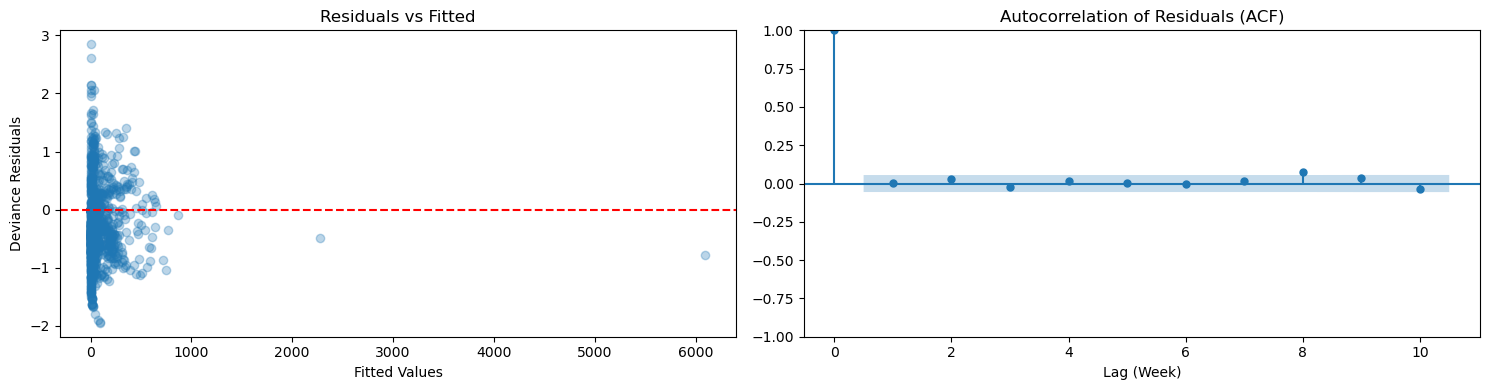

temprange RR range: 0.356 to 2.572


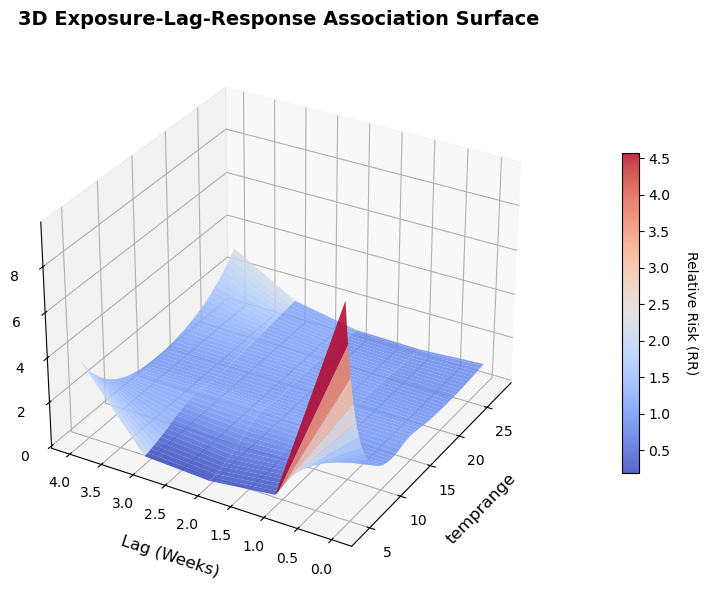

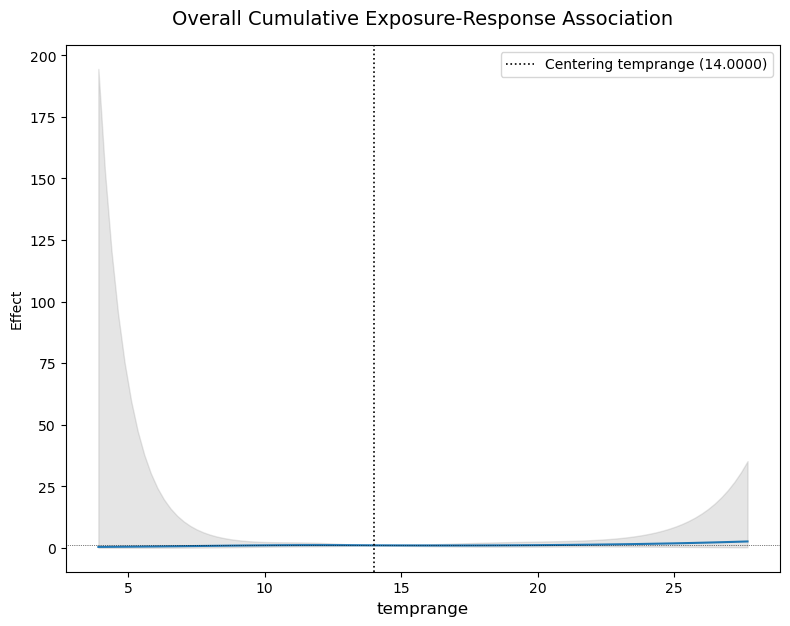

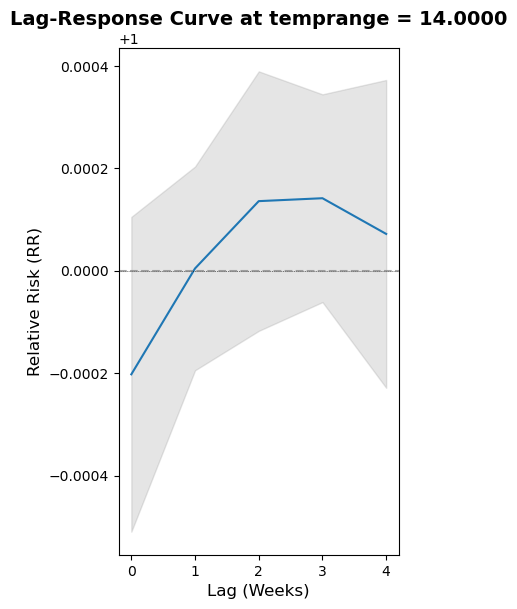


================================================== Zero-Inflated Negative Binomial ==================================================


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept_mu, beta, psi, alpha]


Output()

Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 140 seconds.


Output()

============================== PyMC ZINB posterior summary (selected parameters) ==============================


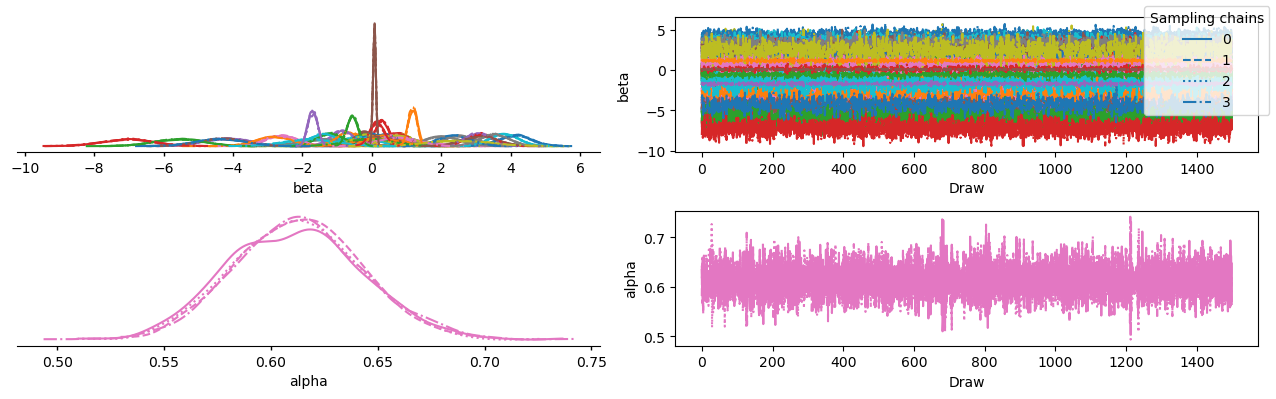

,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta[temprange_basis_0],5739,4874,1.00,0.0058,0.0048
beta[temprange_basis_1],3185,3779,1.00,0.0063,0.0043
beta[temprange_basis_2],4891,4372,1.00,0.0058,0.0047
beta[temprange_basis_3],7102,5049,1.00,0.0046,0.0044
beta[temprange_basis_4],3764,4307,1.00,0.0053,0.0036
beta[temprange_basis_5],5761,5207,1.00,0.0046,0.0039
beta[temprange_basis_6],5619,4850,1.00,0.011,0.0097
beta[temprange_basis_7],3153,3541,1.00,0.013,0.0083
beta[temprange_basis_8],5015,4693,1.00,0.011,0.009
beta[temprange_basis_9],9941,4645,1.00,0.0054,0.0075


Model Metrics


c:\Users\yanss\anaconda3\Lib\site-packages\arviz_stats\loo\loo_helper.py:1169: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


,in_sample_value
n_observations,1248.000000
MAE_predictive_median,7282.905048
RMSE_predictive_mean,47750.761730
mean_prediction_minus_observed,20887.608138
observed_zero_fraction,0.376603
predicted_zero_fraction,0.045387
zero_event_Brier_score,0.309921
coverage_80,0.165865
coverage_95,0.701122
mean_interval_width_80,53645.690224


,value
divergences,0.000000
max_r_hat,1.001867
min_bulk_ESS,3153.392572
min_tail_ESS,3541.966325


Computed; inspect Pareto-k diagnostics. 
This is not leave-future-out validation.


Computed from 6000 posterior samples and 1248 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -4170.21    96.52
p_loo       45.53        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)     1246   99.8%
   (0.70, 1]   (bad)         2    0.2%
    (1, Inf)   (very bad)    0    0.0%


============================== Residual diagnostics (ZINB) ==============================


,1,2,3,4,5,6,7,8,9,10
Pearson_residual_ACF,0.18249,0.177271,0.147116,0.08257,0.077273,0.125451,0.07143,0.084163,0.067305,0.077048


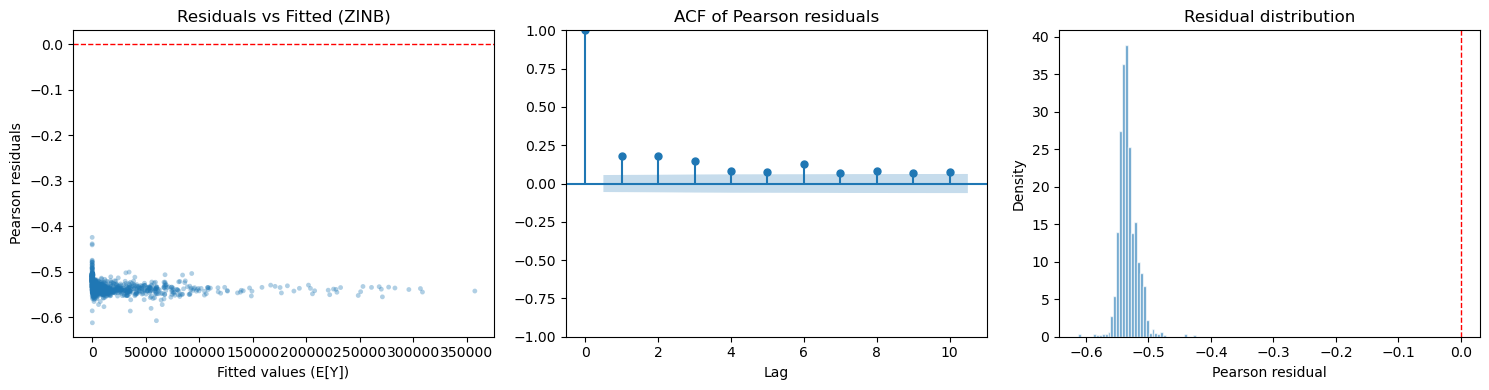

Pearson residual mean   : -0.5329
Pearson residual std    : 0.0147
Proportion of zeros in y: 0.377
Posterior mean psi      : 0.994
temprange RR range: 0.676 to 4.063


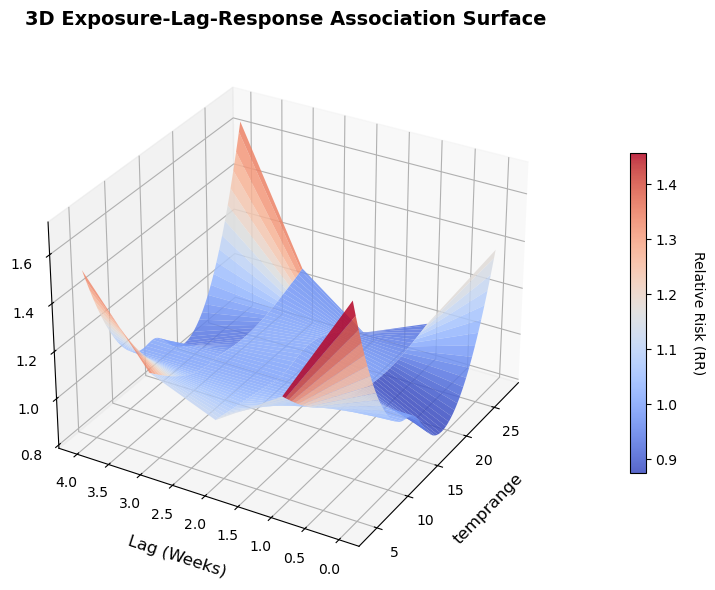

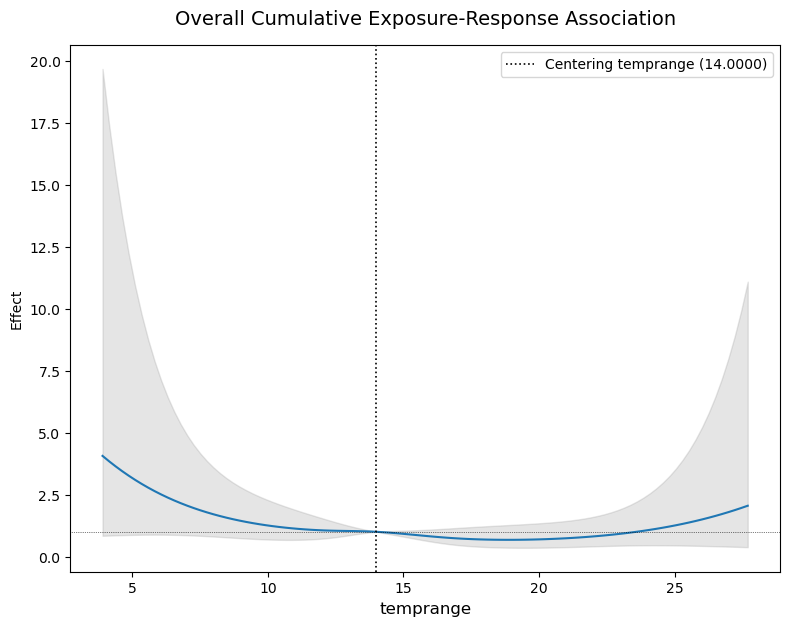

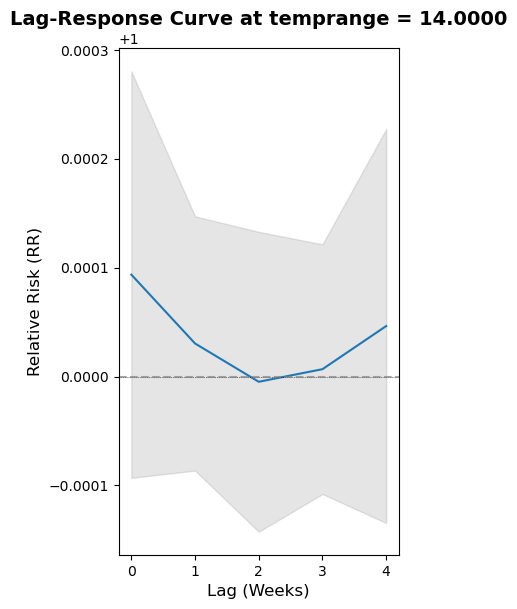

In [87]:
# Test 
tar_var = "H1"
exp = mete_col[0]
exp_col_list = [exp]

display(Markdown(f"**{'='*70} {exp} {'='*70}**"))

idata, pred, model_data, cb_list, colnames, nb_result, resid, report = DLNM_ZINB(
    df, max_lag=4,
    tar_var=tar_var, exp_col_list=exp_col_list, linear_predictors_list=linear_predictors_list,
    bs_name_lst=bs_name_lst, ccs_name_lst=ccs_name_lst,
    cb_grid=cb_grid, smoother_grid=smoother_grid, disp_grid=disp_grid, criterion_lst=[],
    # PyMC controls – reduce draws/tune for a quick test
    draws=1500, tune=1500, target_accept=0.95, chains=4, cores=4, psi_prior="logistic", prior_sigma=1.0
)


**============================== temp (ZINB) ==============================**

============================== Hyperparameter tuning ==============================
=============== Tuning CrossBasis settings ===============
BIC for (2, 3, 2, 3): 10313.06
BIC for (2, 3, 2, 4): 10326.85
BIC for (2, 3, 3, 3): 10313.06
BIC for (2, 3, 3, 4): 10326.85
BIC for (2, 4, 2, 3): 10316.25
BIC for (2, 4, 2, 4): 10339.10
BIC for (2, 4, 3, 3): 10316.25
BIC for (2, 4, 3, 4): 10339.10
BIC for (3, 3, 2, 3): 10313.06
BIC for (3, 3, 2, 4): 10326.85
BIC for (3, 3, 3, 3): 10313.06
BIC for (3, 3, 3, 4): 10326.85
BIC for (3, 4, 2, 3): 10316.25
BIC for (3, 4, 2, 4): 10339.10
BIC for (3, 4, 3, 3): 10316.25
BIC for (3, 4, 3, 4): 10339.10
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10313.06)

=============== Tuning smoother degrees of freedom ===============
Degrees of freedom (8, 4, 5): BIC=9338.3869 | sum(EDF)=25.9135
Degrees of freedom (8, 4, 6): BIC=9342.0687 | sum(EDF)=26.8663
Degrees of freedom (8, 4, 7): BIC=9345.4340 | sum(EDF)=27.7642
Degrees of freedom (8, 5, 5): BIC=9338.3869 | sum

,alpha,AIC,BIC,GCV,EDF
KFold,"(3162.2776601683795, 3162.2776601683795, 125.8...",8116.639732,8314.79812,1.064909,38.632656



=============== Tuning Negative Binomial dispersion parameter ===============
Dispersion   1.5: Pearson ratio = 1.1661 | BIC = 8302.5478
Dispersion   2.0: Pearson ratio = 0.9521 | BIC = 8364.7192
Dispersion   3.0: Pearson ratio = 0.6951 | BIC = 8531.3299
Dispersion   4.0: Pearson ratio = 0.5607 | BIC = 8705.3748
Dispersion   5.0: Pearson ratio = 0.4782 | BIC = 8868.9765

Best dispersion parameter: 2.0 (Pearson ratio = 0.9521)

============================== Negative Binomial GLMGam ==============================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1210.44
Model Family:        NegativeBinomial   Df Model:                        36.56
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -4048.5
Date:  

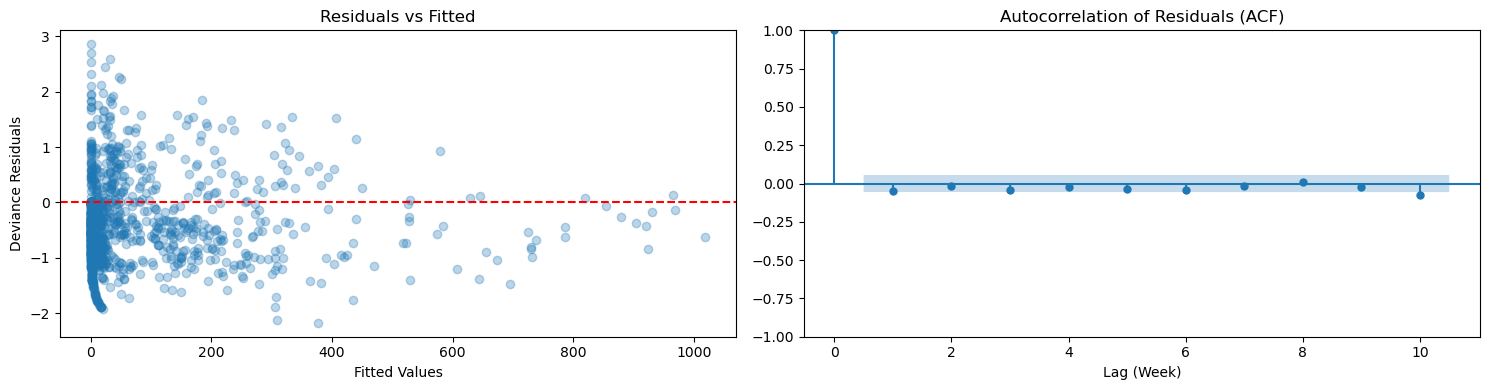

temp RR range: 0.959 to 21.574


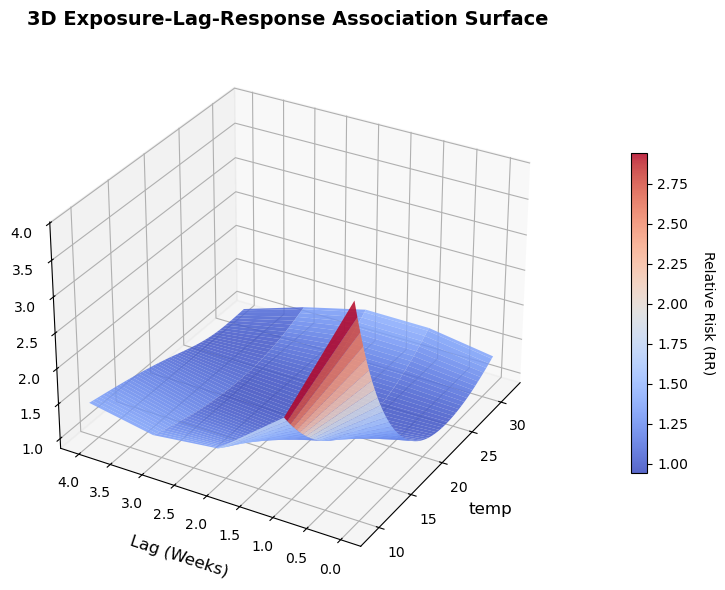

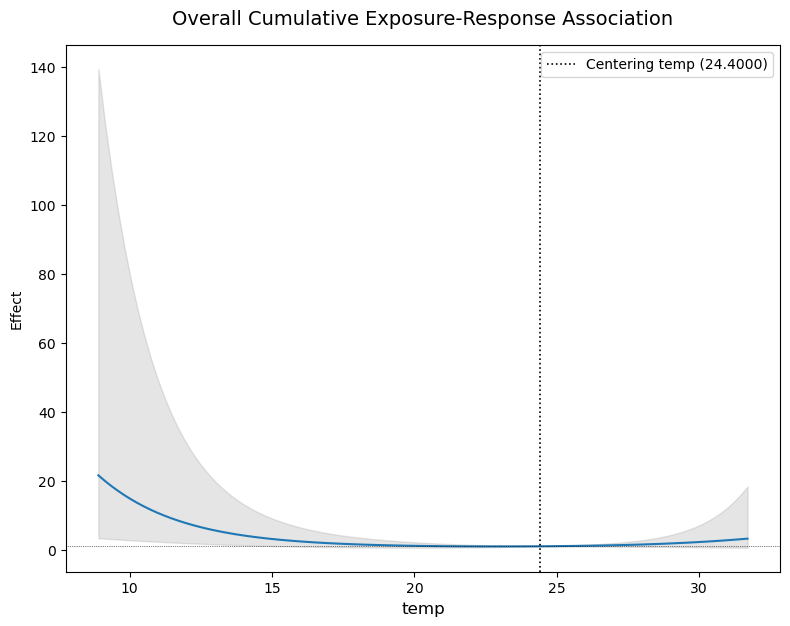

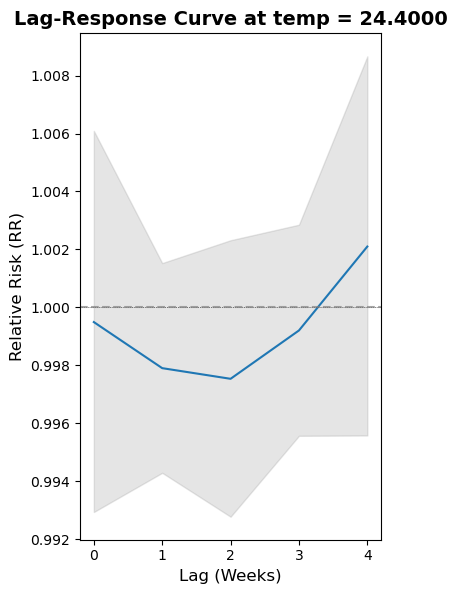


============================== Zero-Inflated Negative Binomial ==============================


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept_mu, beta, psi, alpha]


Output()

Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 217 seconds.


Output()

IN-SAMPLE metrics: not a forecast-performance estimate.


... (2 outputs left out)

,value
divergences,0.000000
max_r_hat,1.001886
min_bulk_ESS,2162.843662
min_tail_ESS,2995.074870


,Pearson_residual_ACF
1,0.059963
2,0.070919
3,0.031571
4,-0.001460
5,-0.003409
6,0.008125
7,-0.022429
8,-0.025208
9,-0.051607
10,0.001953


Computed; inspect Pareto-k diagnostics. This is not leave-future-out validation.
Computed from 6000 posterior samples and 1248 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -4163.91    96.37
p_loo       42.51        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)     1247   99.9%
   (0.70, 1]   (bad)         1    0.1%
    (1, Inf)   (very bad)    0    0.0%



,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta[temp_basis_0],7975,5061,1.00,0.0056,0.0062
beta[temp_basis_1],2525,3347,1.00,0.0066,0.0038
beta[temp_basis_2],6135,4388,1.00,0.0057,0.0052
beta[temp_basis_3],9065,4869,1.00,0.0075,0.0094
beta[temp_basis_4],3581,3690,1.00,0.0098,0.0072
beta[temp_basis_5],7307,4869,1.00,0.0084,0.0088
beta[temp_basis_6],8183,5051,1.00,0.0057,0.0065
beta[temp_basis_7],2511,3280,1.00,0.0074,0.0046
beta[temp_basis_8],6897,5254,1.00,0.0051,0.0051
beta[pandemic_flag],5027,4702,1.00,0.0065,0.0056


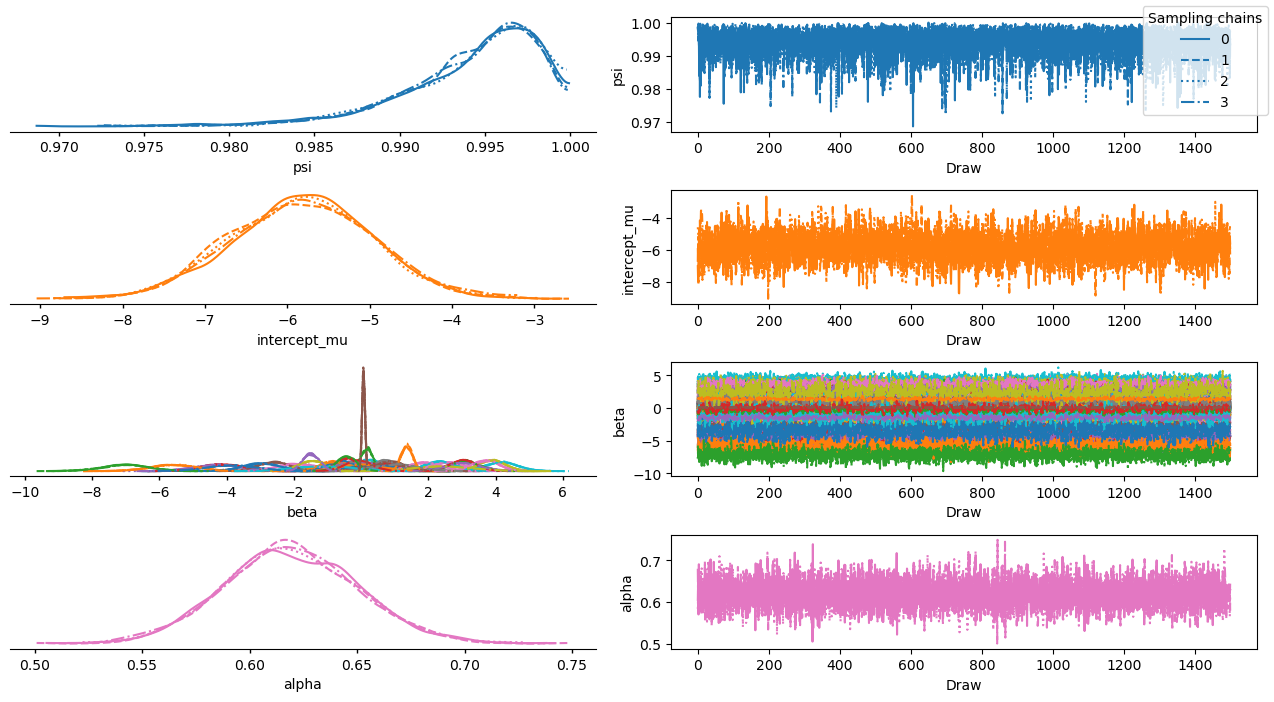


--- Residual diagnostics (ZINB) ---


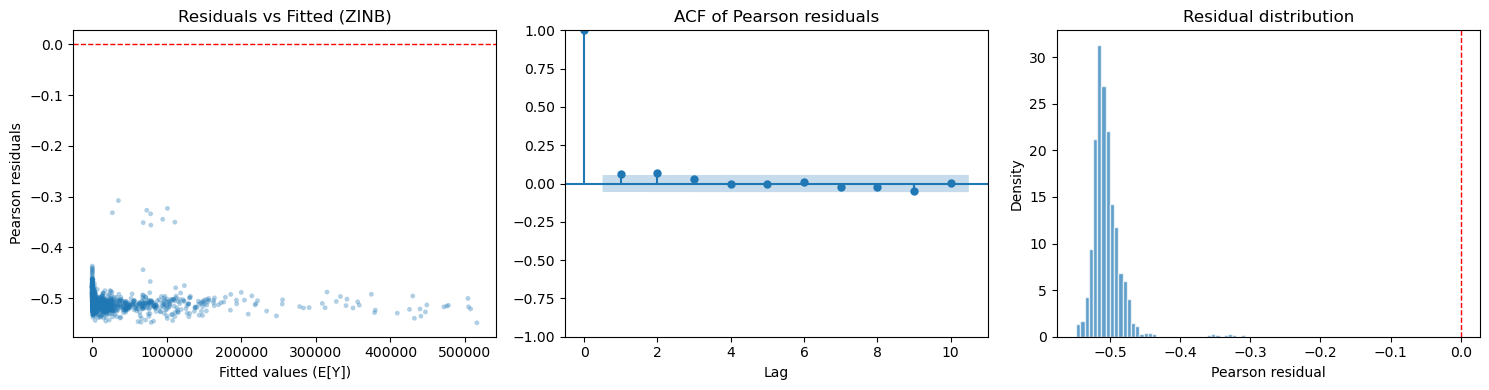

Pearson residual mean   : -0.5057
Pearson residual std    : 0.0217
Proportion of zeros in y: 0.377
Posterior mean psi      : 0.994
temp RR range: 0.749 to 8.003


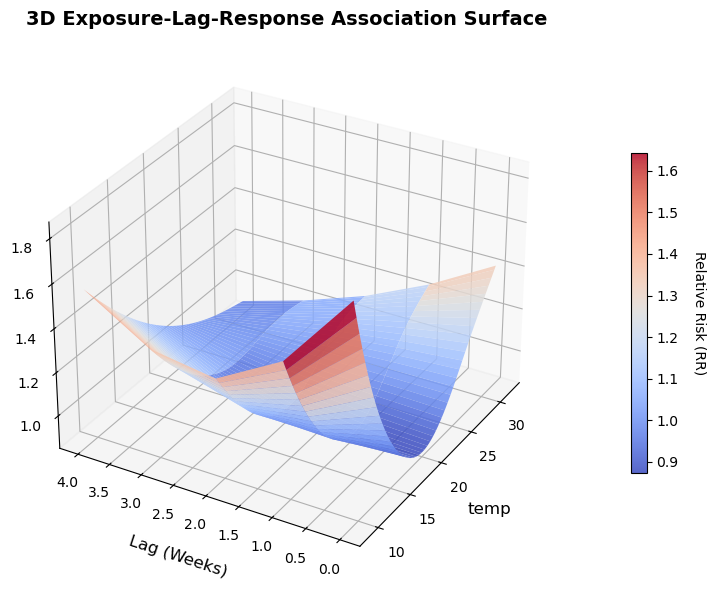

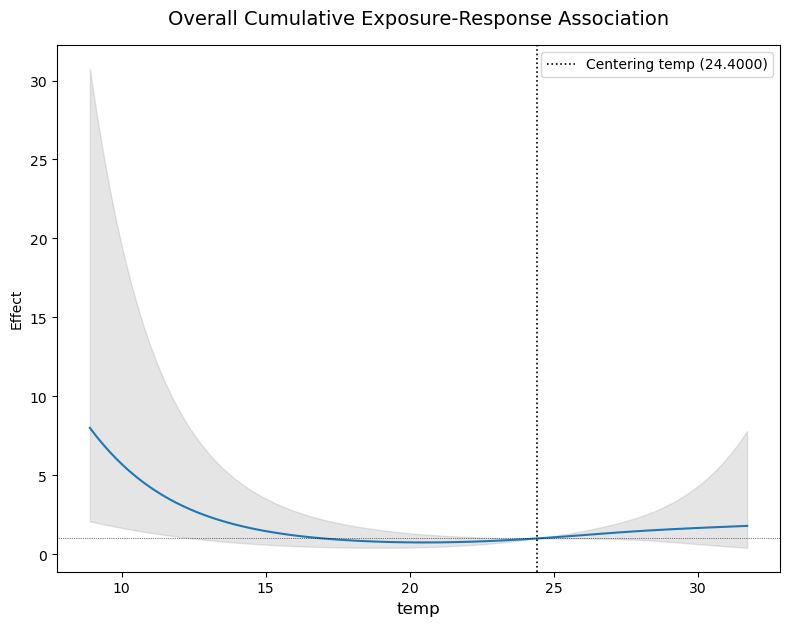

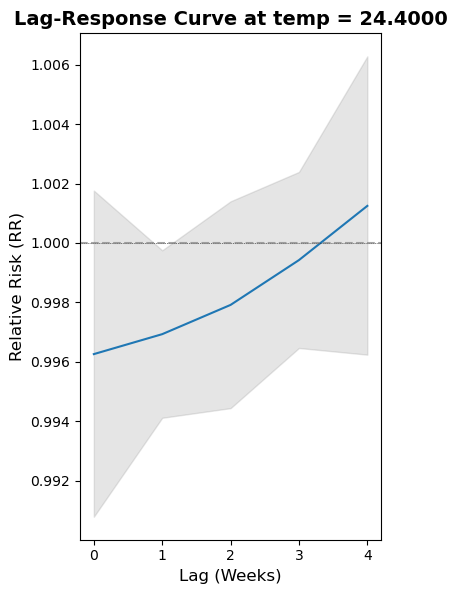

**============================== RH (ZINB) ==============================**

============================== Hyperparameter tuning ==============================
=============== Tuning CrossBasis settings ===============
BIC for (2, 3, 2, 3): 10395.59
BIC for (2, 3, 2, 4): 10403.25
BIC for (2, 3, 3, 3): 10395.59
BIC for (2, 3, 3, 4): 10403.25
BIC for (2, 4, 2, 3): 10405.35
BIC for (2, 4, 2, 4): 10412.03
BIC for (2, 4, 3, 3): 10405.35
BIC for (2, 4, 3, 4): 10412.03
BIC for (3, 3, 2, 3): 10395.59
BIC for (3, 3, 2, 4): 10403.25
BIC for (3, 3, 3, 3): 10395.59
BIC for (3, 3, 3, 4): 10403.25
BIC for (3, 4, 2, 3): 10405.35
BIC for (3, 4, 2, 4): 10412.03
BIC for (3, 4, 3, 3): 10405.35
BIC for (3, 4, 3, 4): 10412.03
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10395.59)

=============== Tuning smoother degrees of freedom ===============
Degrees of freedom (8, 4, 5): BIC=9354.8875 | sum(EDF)=25.4168
Degrees of freedom (8, 4, 6): BIC=9322.0322 | sum(EDF)=26.5008
Degrees of freedom (8, 4, 7): BIC=9334.7831 | sum(EDF)=29.6526
Degrees of freedom (8, 5, 5): BIC=9354.8875 | sum

,alpha,AIC,BIC,GCV,EDF
KFold,"(3162.2776601683795, 125.89254117941663, 125.8...",8127.059571,8500.414112,1.127709,72.78863



=============== Tuning Negative Binomial dispersion parameter ===============
Dispersion   1.5: Pearson ratio = 1.1510 | BIC = 8342.2026
Dispersion   2.0: Pearson ratio = 0.9370 | BIC = 8348.7121
Dispersion   3.0: Pearson ratio = 0.7035 | BIC = 8401.8328
Dispersion   4.0: Pearson ratio = 0.5876 | BIC = 8667.9117
Dispersion   5.0: Pearson ratio = 0.5080 | BIC = 8841.2516

Best dispersion parameter: 2.0 (Pearson ratio = 0.9370)

============================== Negative Binomial GLMGam ==============================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1208.32
Model Family:        NegativeBinomial   Df Model:                        38.68
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -4032.9
Date:  

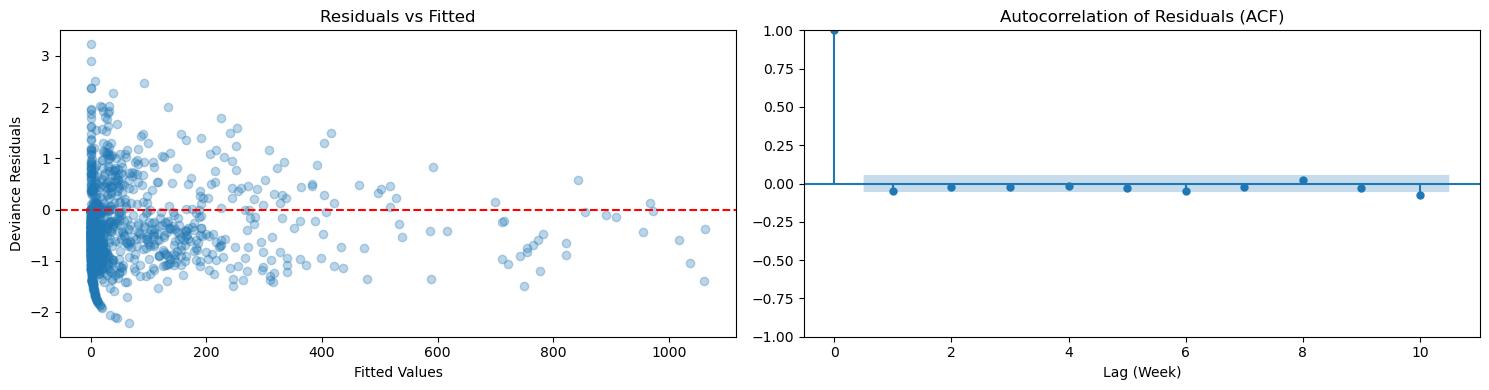

RH RR range: 0.253 to 2.482


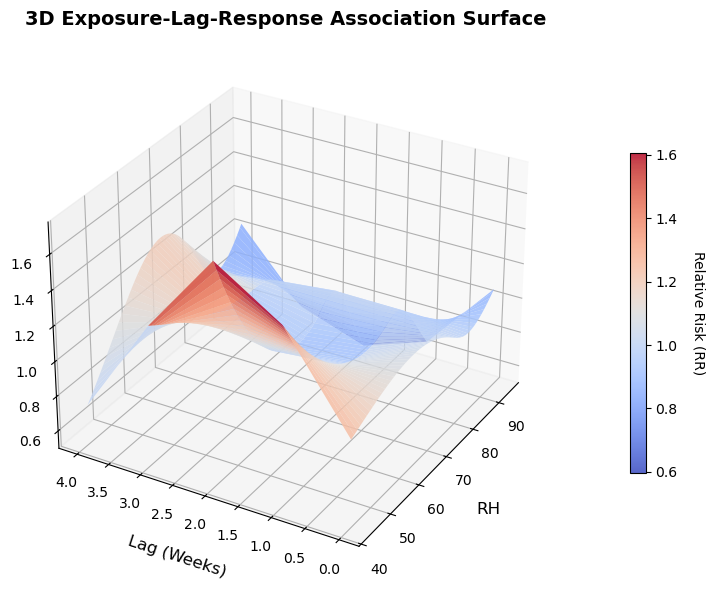

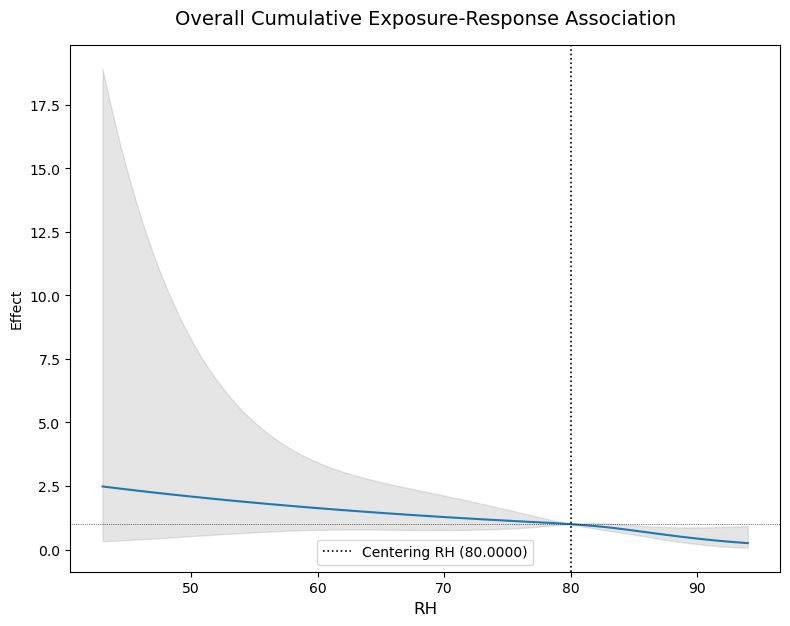

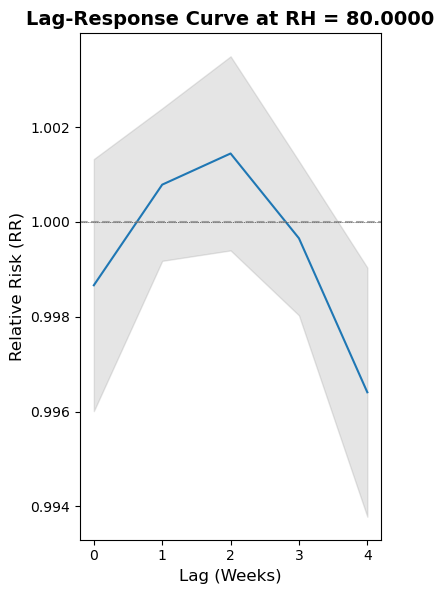


============================== Zero-Inflated Negative Binomial ==============================


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept_mu, beta, psi, alpha]


Output()

Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 223 seconds.


Output()

IN-SAMPLE metrics: not a forecast-performance estimate.


... (2 outputs left out)

,value
divergences,0.000000
max_r_hat,1.002393
min_bulk_ESS,2990.974676
min_tail_ESS,3615.190009


,Pearson_residual_ACF
1,0.185571
2,0.143714
3,0.122709
4,0.044895
5,0.003548
6,0.042475
7,-0.006971
8,-0.006000
9,-0.048353
10,-0.000805


Computed; inspect Pareto-k diagnostics. This is not leave-future-out validation.
Computed from 6000 posterior samples and 1248 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -4158.23    96.36
p_loo       45.33        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)     1246   99.8%
   (0.70, 1]   (bad)         2    0.2%
    (1, Inf)   (very bad)    0    0.0%



,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta[RH_basis_0],5089,4695,1.00,0.004,0.0034
beta[RH_basis_1],3320,4185,1.00,0.0039,0.0025
beta[RH_basis_2],5491,4638,1.00,0.0033,0.0029
beta[RH_basis_3],5756,4611,1.00,0.01,0.009
beta[RH_basis_4],3613,3615,1.00,0.011,0.0073
beta[RH_basis_5],5024,4616,1.00,0.0097,0.0078
beta[RH_basis_6],5911,4538,1.00,0.004,0.0037
beta[RH_basis_7],3747,4325,1.00,0.0041,0.0028
beta[RH_basis_8],5926,4883,1.00,0.0034,0.003
beta[pandemic_flag],5161,4482,1.00,0.0065,0.0054


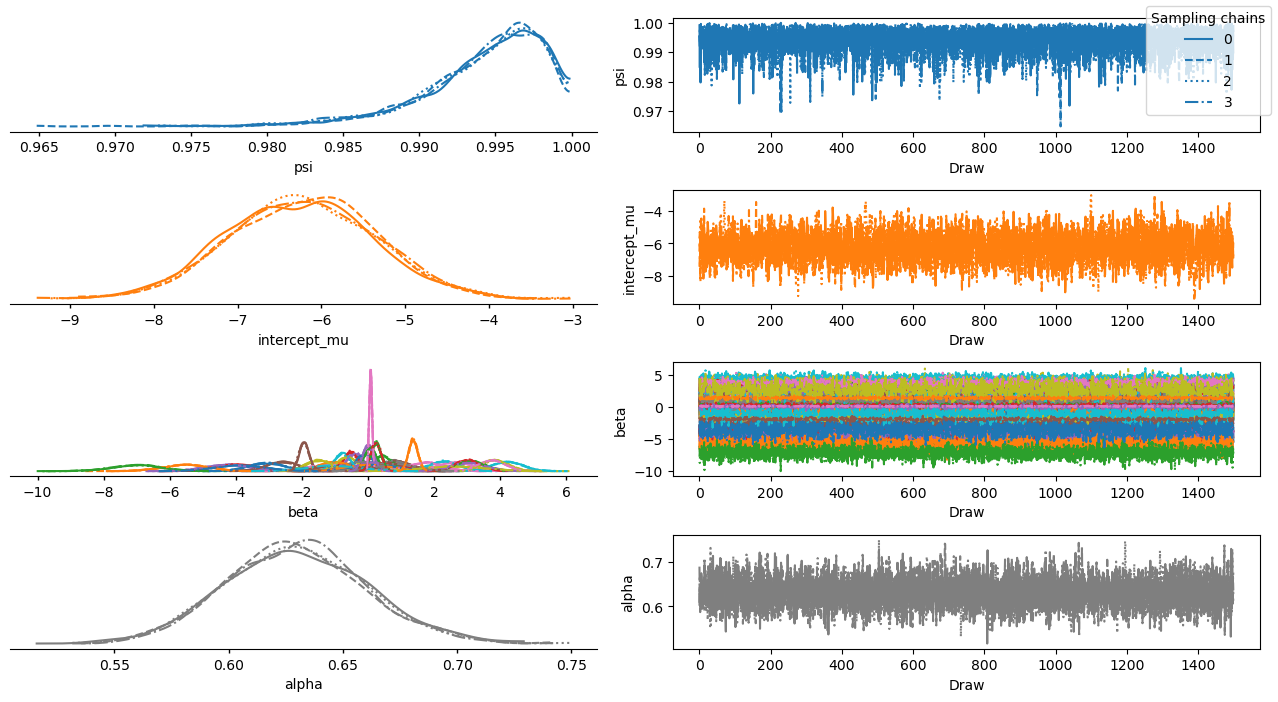


--- Residual diagnostics (ZINB) ---


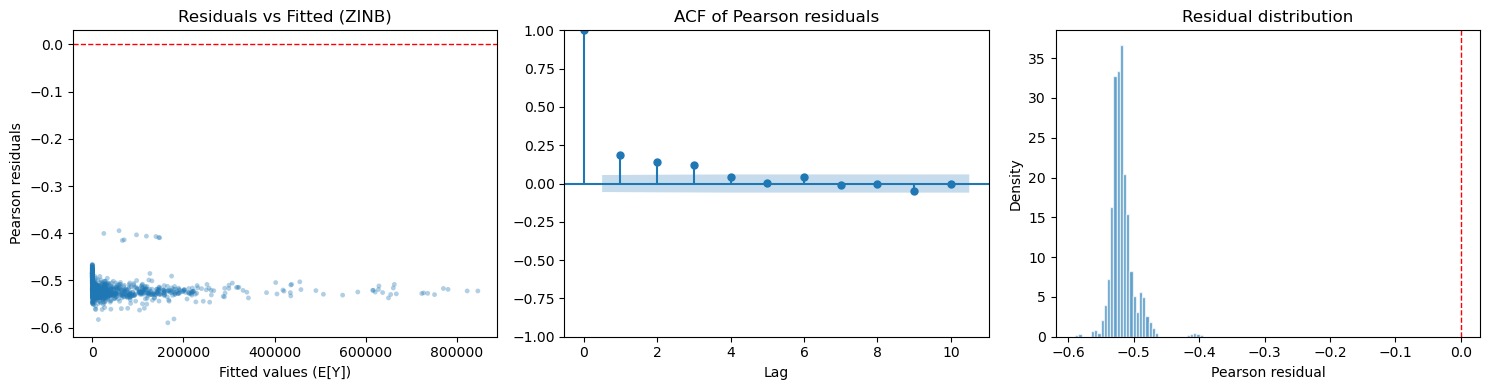

Pearson residual mean   : -0.5180
Pearson residual std    : 0.0181
Proportion of zeros in y: 0.377
Posterior mean psi      : 0.994
RH RR range: 0.314 to 3.268


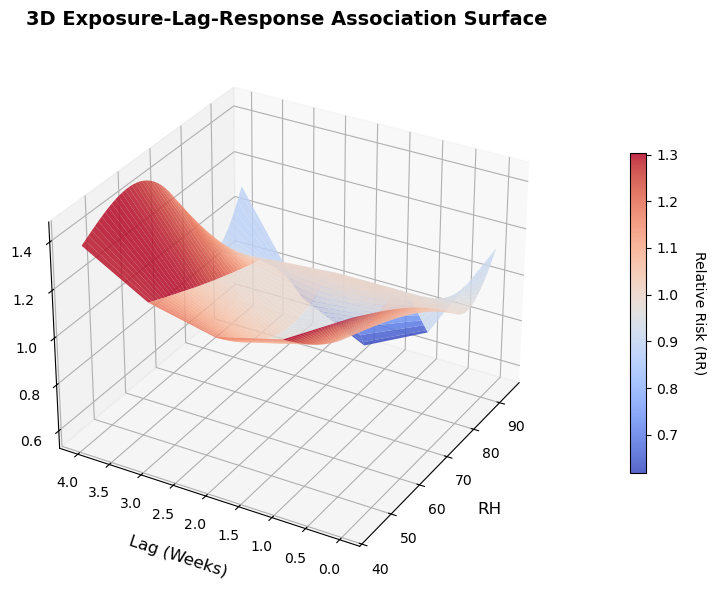

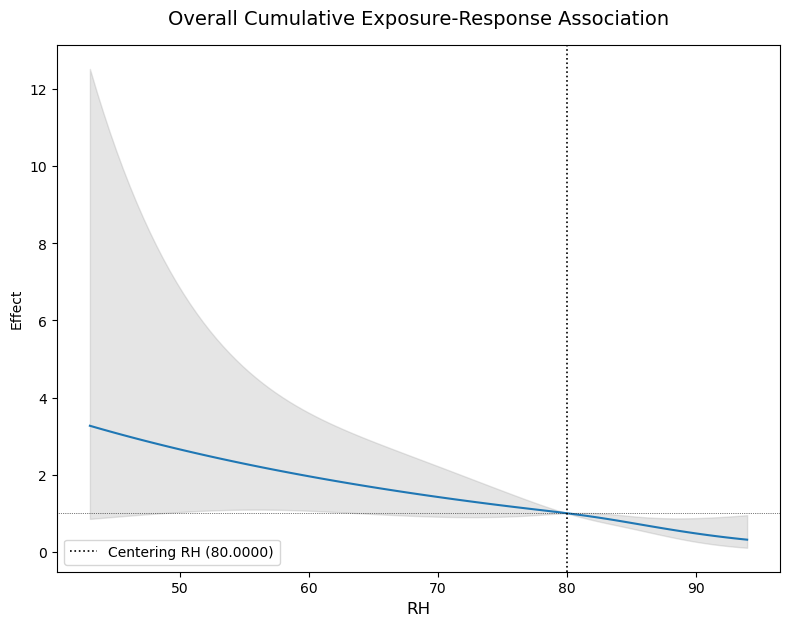

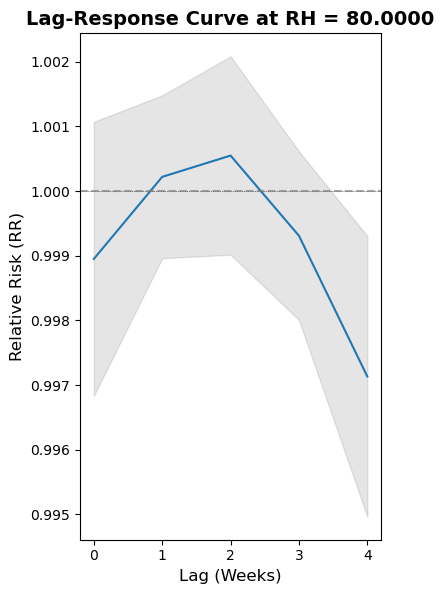

**============================== SR (ZINB) ==============================**

============================== Hyperparameter tuning ==============================
=============== Tuning CrossBasis settings ===============
BIC for (2, 3, 2, 3): 10392.35
BIC for (2, 3, 2, 4): 10400.31
BIC for (2, 3, 3, 3): 10392.35
BIC for (2, 3, 3, 4): 10400.31
BIC for (2, 4, 2, 3): 10400.90
BIC for (2, 4, 2, 4): 10411.69
BIC for (2, 4, 3, 3): 10400.90
BIC for (2, 4, 3, 4): 10411.69
BIC for (3, 3, 2, 3): 10392.35
BIC for (3, 3, 2, 4): 10400.31
BIC for (3, 3, 3, 3): 10392.35
BIC for (3, 3, 3, 4): 10400.31
BIC for (3, 4, 2, 3): 10400.90
BIC for (3, 4, 2, 4): 10411.69
BIC for (3, 4, 3, 3): 10400.90
BIC for (3, 4, 3, 4): 10411.69
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10392.35)

=============== Tuning smoother degrees of freedom ===============
Degrees of freedom (8, 4, 5): BIC=9342.6136 | sum(EDF)=26.7543
Degrees of freedom (8, 4, 6): BIC=9311.8733 | sum(EDF)=27.7306
Degrees of freedom (8, 4, 7): BIC=9308.5805 | sum(EDF)=28.7905
Degrees of freedom (8, 5, 5): BIC=9342.6136 | sum

,alpha,AIC,BIC,GCV,EDF
KFold,"(630.957344480193, 1.0, 3162.2776601683795)",8030.271332,8243.902846,1.070242,41.649273



=============== Tuning Negative Binomial dispersion parameter ===============
Dispersion   1.5: Pearson ratio = 1.0882 | BIC = 8244.0595
Dispersion   2.0: Pearson ratio = 0.8753 | BIC = 8328.3669
Dispersion   3.0: Pearson ratio = 0.6413 | BIC = 8510.1013
Dispersion   4.0: Pearson ratio = 0.5148 | BIC = 8701.4977
Dispersion   5.0: Pearson ratio = 0.4342 | BIC = 8871.6908

Best dispersion parameter: 1.5 (Pearson ratio = 1.0882)

============================== Negative Binomial GLMGam ==============================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1208.43
Model Family:        NegativeBinomial   Df Model:                        38.57
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -3981.0
Date:  

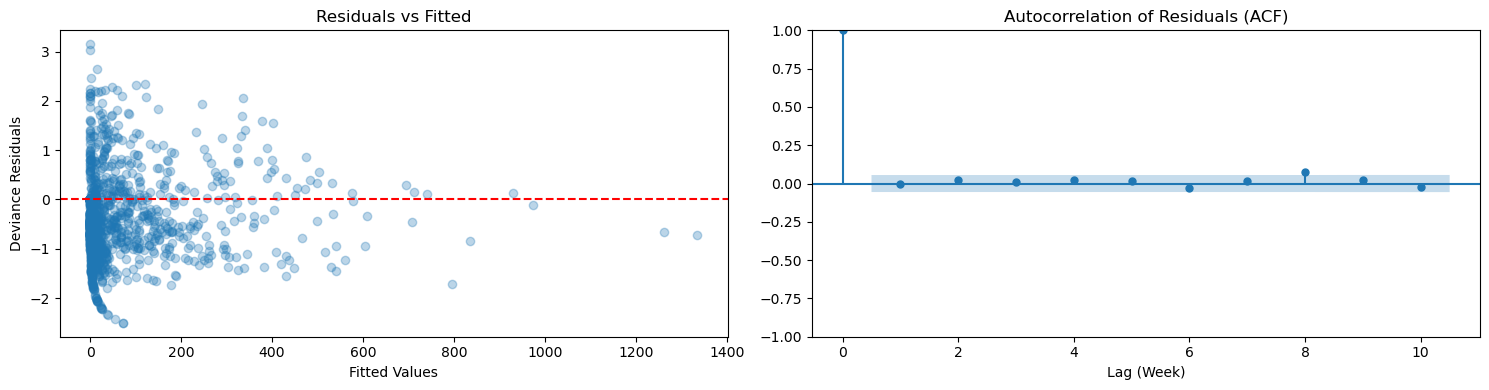

SR RR range: 0.992 to 7.902


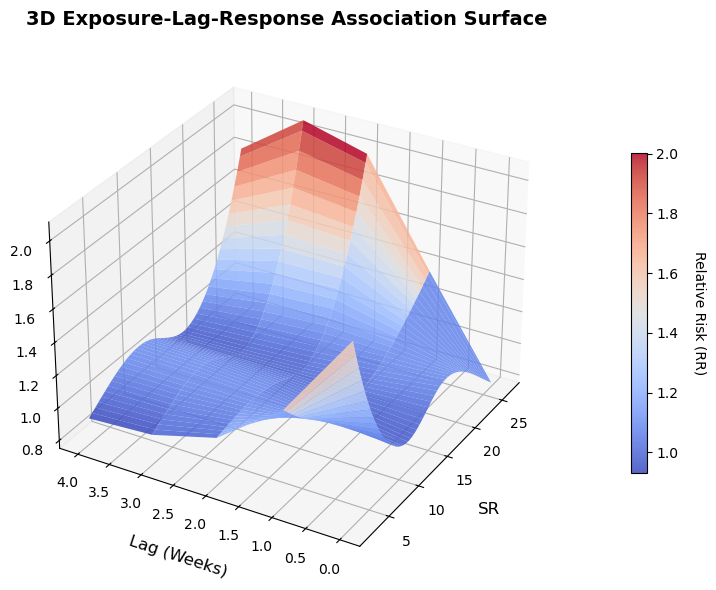

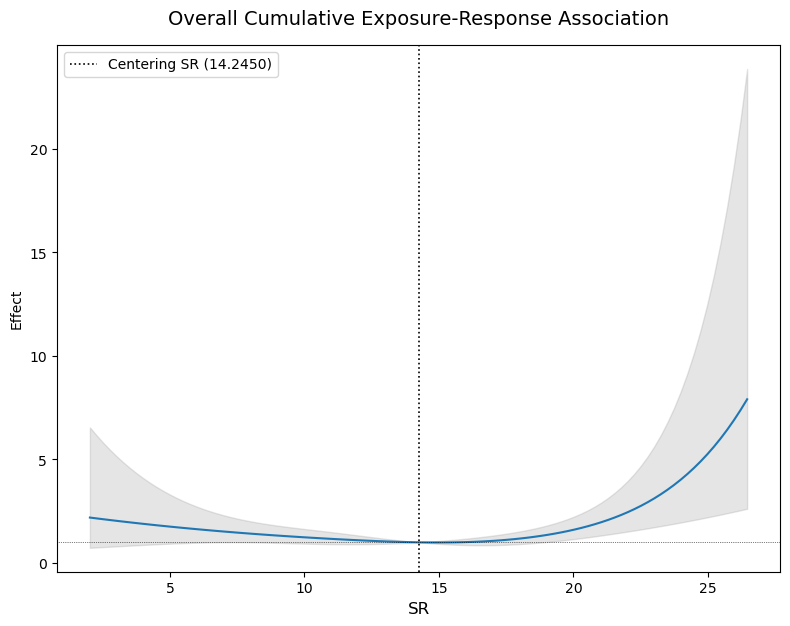

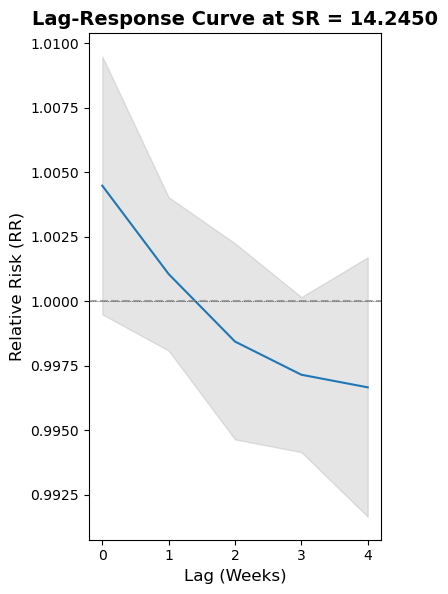


============================== Zero-Inflated Negative Binomial ==============================


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept_mu, beta, psi, alpha]


Output()

Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 183 seconds.


Output()

IN-SAMPLE metrics: not a forecast-performance estimate.


... (2 outputs left out)

,value
divergences,0.000000
max_r_hat,1.001688
min_bulk_ESS,3715.748234
min_tail_ESS,4040.541832


,Pearson_residual_ACF
1,0.087698
2,0.101688
3,0.131356
4,0.065256
5,0.033897
6,0.072372
7,0.014289
8,0.031087
9,0.020474
10,0.045069


Computed; inspect Pareto-k diagnostics. This is not leave-future-out validation.
Computed from 6000 posterior samples and 1248 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -4161.59    96.40
p_loo       46.02        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)     1246   99.8%
   (0.70, 1]   (bad)         2    0.2%
    (1, Inf)   (very bad)    0    0.0%



,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta[SR_basis_0],10456,4727,1.00,0.0023,0.0032
beta[SR_basis_1],7868,4623,1.00,0.0021,0.0024
beta[SR_basis_2],10862,4799,1.00,0.0019,0.0029
beta[SR_basis_3],8897,5094,1.00,0.0061,0.0077
beta[SR_basis_4],6600,5067,1.00,0.0058,0.0057
beta[SR_basis_5],8646,4824,1.00,0.0052,0.0061
beta[SR_basis_6],9902,4901,1.00,0.0032,0.004
beta[SR_basis_7],5935,4610,1.00,0.0033,0.0028
beta[SR_basis_8],8097,4901,1.00,0.0028,0.0029
beta[pandemic_flag],6990,4782,1.00,0.0055,0.0055


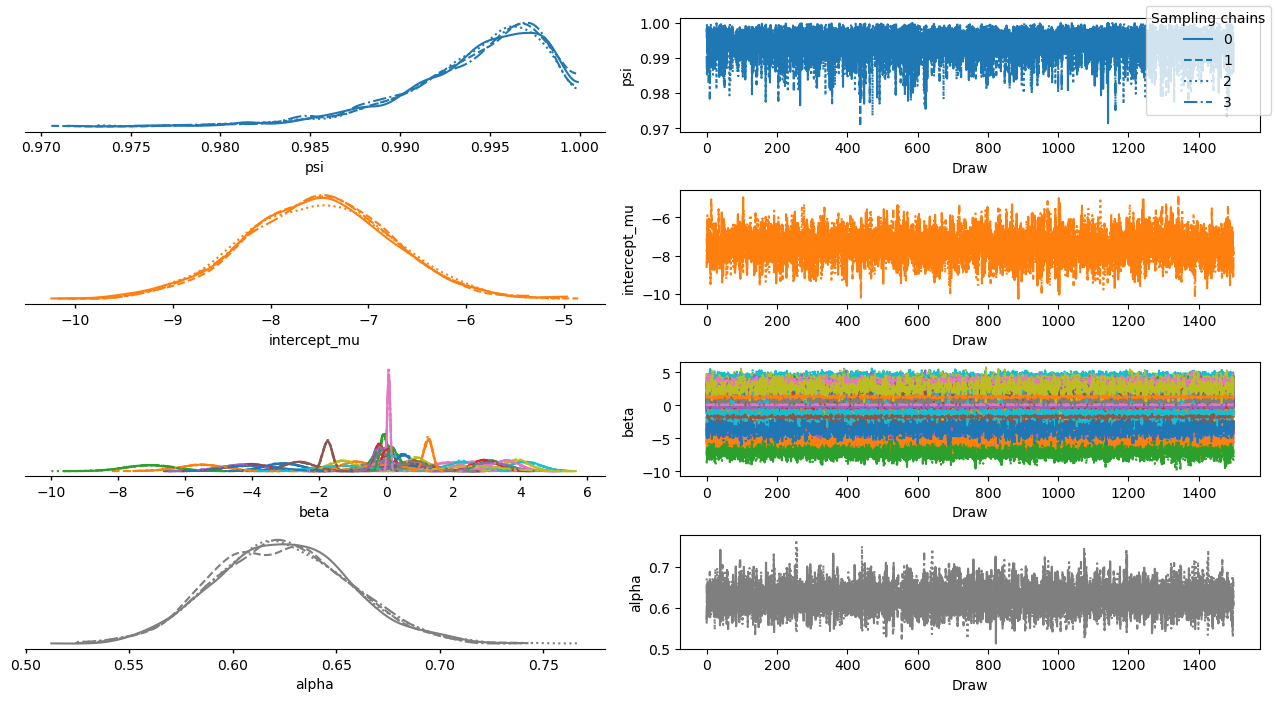


--- Residual diagnostics (ZINB) ---


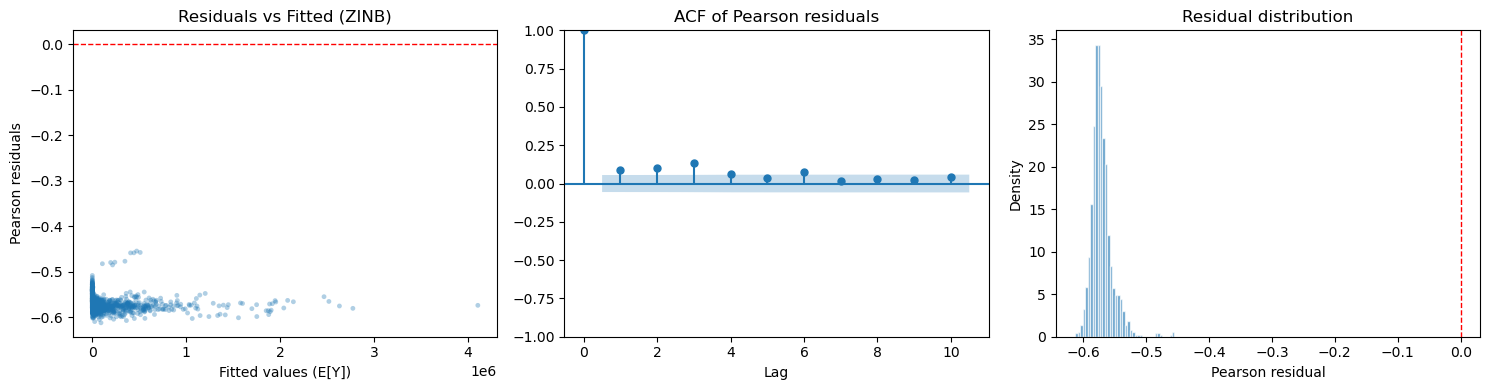

Pearson residual mean   : -0.5708
Pearson residual std    : 0.0171
Proportion of zeros in y: 0.377
Posterior mean psi      : 0.994
SR RR range: 0.969 to 2.298


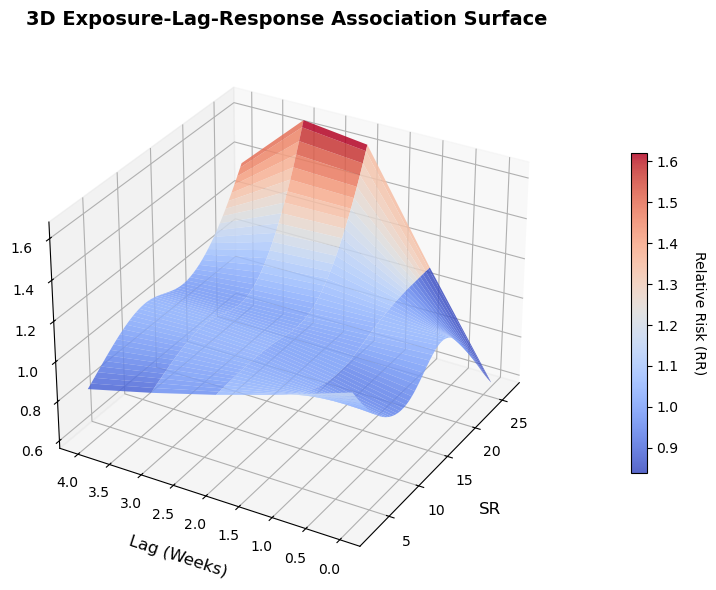

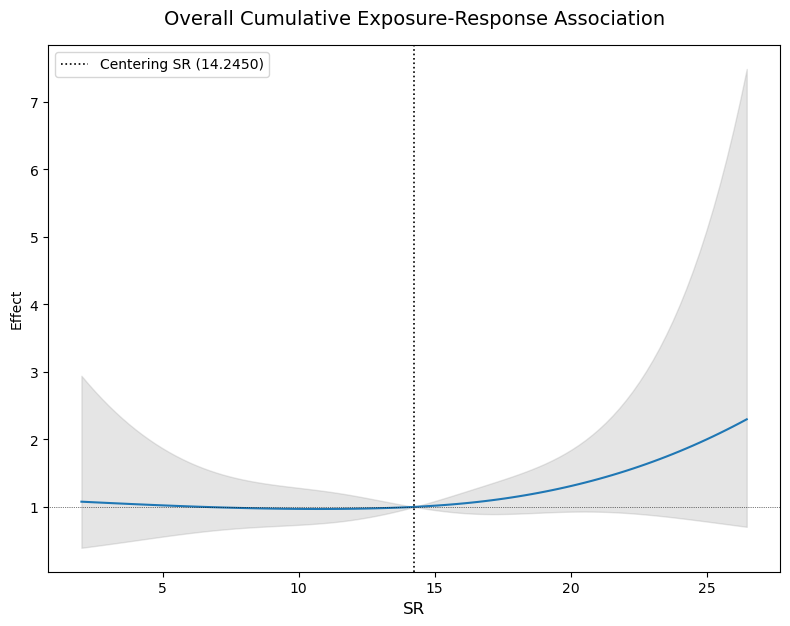

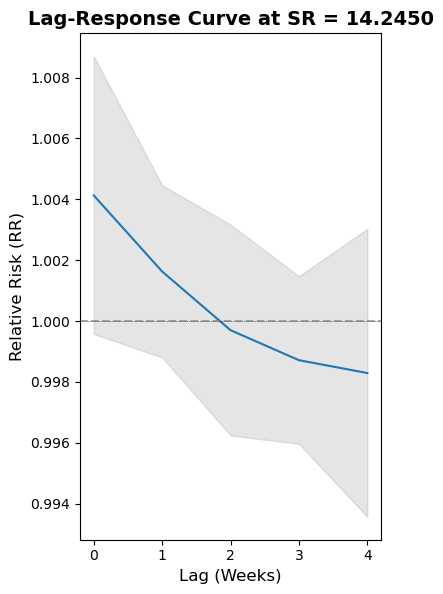

**============================== AP (ZINB) ==============================**

============================== Hyperparameter tuning ==============================
=============== Tuning CrossBasis settings ===============
BIC for (2, 3, 2, 3): 10422.18
BIC for (2, 3, 2, 4): 10441.07
BIC for (2, 3, 3, 3): 10422.18
BIC for (2, 3, 3, 4): 10441.07
BIC for (2, 4, 2, 3): 10436.31
BIC for (2, 4, 2, 4): 10462.98
BIC for (2, 4, 3, 3): 10436.31
BIC for (2, 4, 3, 4): 10462.98
BIC for (3, 3, 2, 3): 10422.18
BIC for (3, 3, 2, 4): 10441.07
BIC for (3, 3, 3, 3): 10422.18
BIC for (3, 3, 3, 4): 10441.07
BIC for (3, 4, 2, 3): 10436.31
BIC for (3, 4, 2, 4): 10462.98
BIC for (3, 4, 3, 3): 10436.31
BIC for (3, 4, 3, 4): 10462.98
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10422.18)

=============== Tuning smoother degrees of freedom ===============
Degrees of freedom (8, 4, 5): BIC=9358.6154 | sum(EDF)=26.6529
Degrees of freedom (8, 4, 6): BIC=9343.8616 | sum(EDF)=27.7506
Degrees of freedom (8, 4, 7): BIC=9340.4847 | sum(EDF)=28.8313
Degrees of freedom (8, 5, 5): BIC=9358.6154 | sum

,alpha,AIC,BIC,GCV,EDF
KFold,"(630.957344480193, 5.011872336272722, 125.8925...",7990.62875,8202.093493,1.069493,41.226843



=============== Tuning Negative Binomial dispersion parameter ===============
Dispersion   1.5: Pearson ratio = 1.0874 | BIC = 8217.4929
Dispersion   2.0: Pearson ratio = 0.8814 | BIC = 8298.6065
Dispersion   3.0: Pearson ratio = 0.6547 | BIC = 8495.7217
Dispersion   4.0: Pearson ratio = 0.5292 | BIC = 8686.3250
Dispersion   5.0: Pearson ratio = 0.4386 | BIC = 8856.5008

Best dispersion parameter: 1.5 (Pearson ratio = 1.0874)

============================== Negative Binomial GLMGam ==============================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1207.08
Model Family:        NegativeBinomial   Df Model:                        39.92
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -3962.9
Date:  

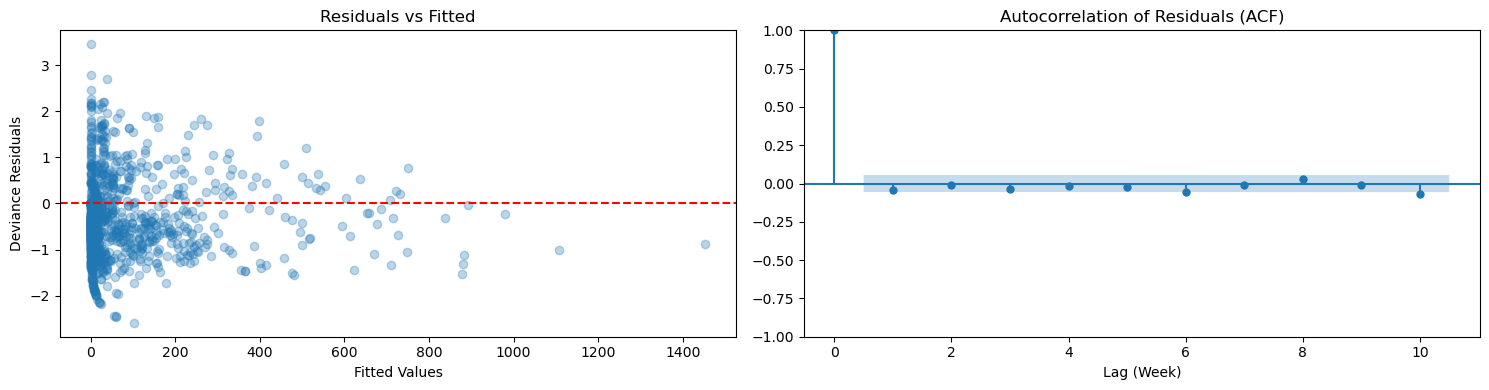

AP RR range: 0.249 to 4.877


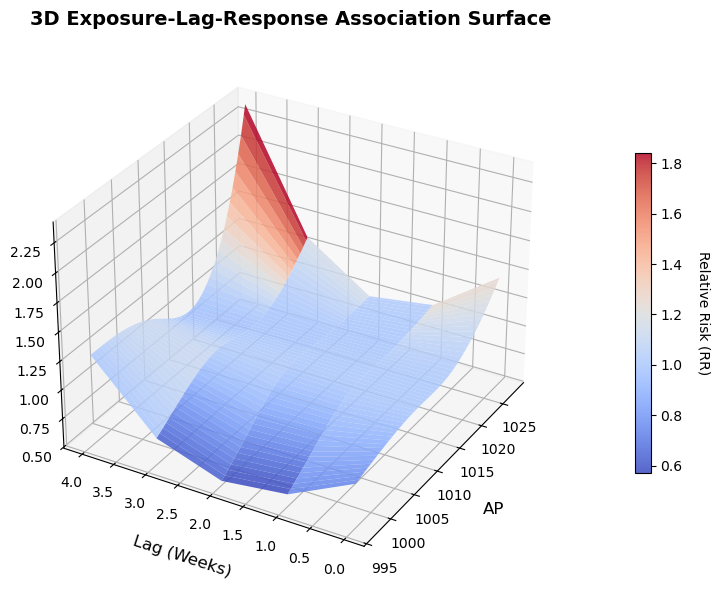

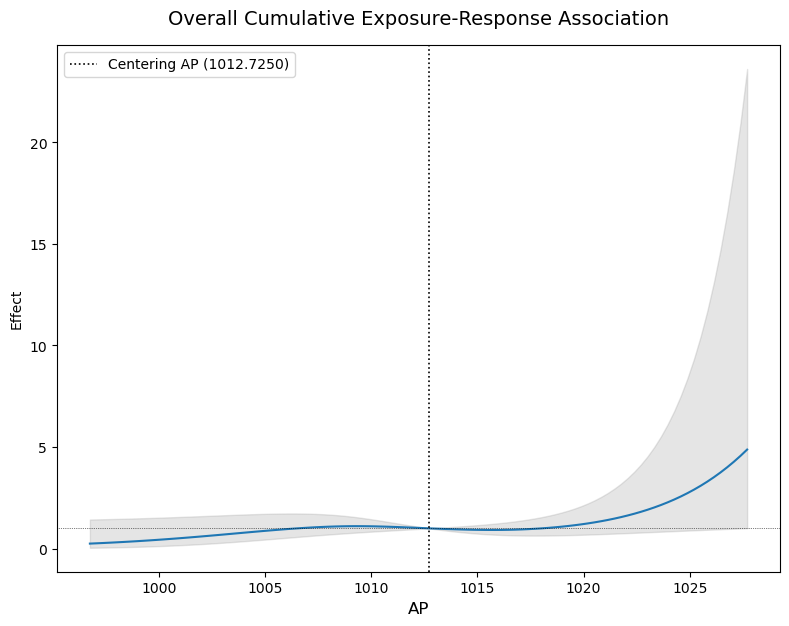

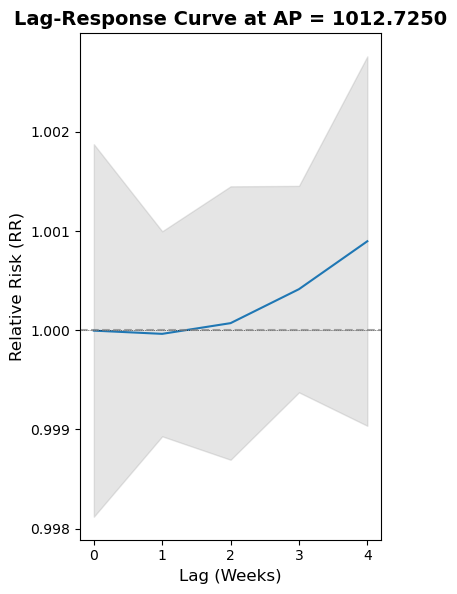


============================== Zero-Inflated Negative Binomial ==============================


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept_mu, beta, psi, alpha]


Output()

Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 177 seconds.


Output()

IN-SAMPLE metrics: not a forecast-performance estimate.


,in_sample_value
n_observations,1248.000000
MAE_predictive_median,36111.701522
RMSE_predictive_mean,209220.161049
mean_prediction_minus_observed,89721.411928
observed_zero_fraction,0.376603
predicted_zero_fraction,0.021132
zero_event_Brier_score,0.346483
coverage_80,0.032051
coverage_95,0.334936
mean_interval_width_80,227741.947756


,value
divergences,0.000000
max_r_hat,1.002112
min_bulk_ESS,4327.319376
min_tail_ESS,3892.729912


,Pearson_residual_ACF
1,0.283546
2,0.241125
3,0.180360
4,0.107952
5,0.061548
6,0.106826
7,0.075199
8,0.083954
9,0.070421
10,0.062342


Computed; inspect Pareto-k diagnostics. This is not leave-future-out validation.
Computed from 6000 posterior samples and 1248 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -4166.21    96.46
p_loo       42.68        -
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)     1248  100.0%
   (0.70, 1]   (bad)         0    0.0%
    (1, Inf)   (very bad)    0    0.0%



,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta[AP_basis_0],8892,4413,1.00,0.0051,0.0067
beta[AP_basis_1],4327,4341,1.00,0.0048,0.0037
beta[AP_basis_2],8143,5152,1.00,0.0045,0.005
beta[AP_basis_3],9313,5234,1.00,0.0078,0.0097
beta[AP_basis_4],4578,4082,1.00,0.0086,0.0068
beta[AP_basis_5],8729,5403,1.00,0.0072,0.0081
beta[AP_basis_6],8255,5301,1.00,0.0049,0.0057
beta[AP_basis_7],5297,4734,1.00,0.0048,0.0038
beta[AP_basis_8],8093,5541,1.00,0.0046,0.0052
beta[pandemic_flag],7196,4062,1.00,0.0048,0.0055


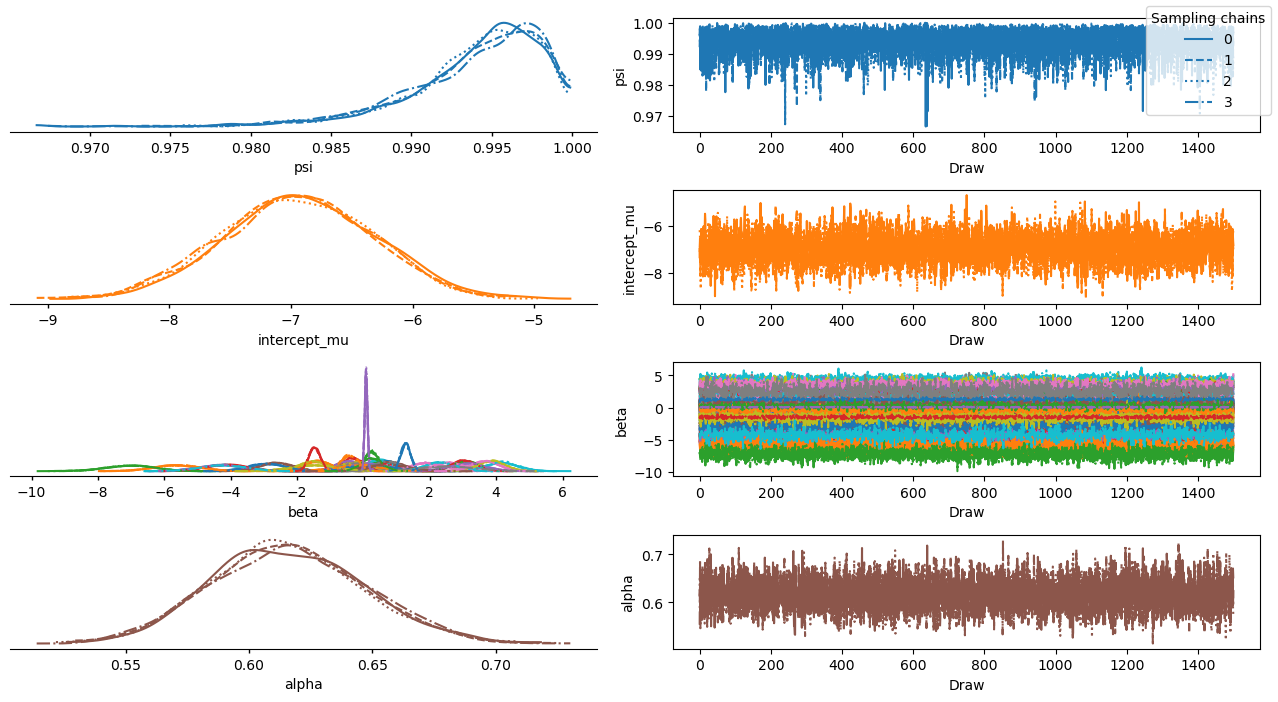


--- Residual diagnostics (ZINB) ---


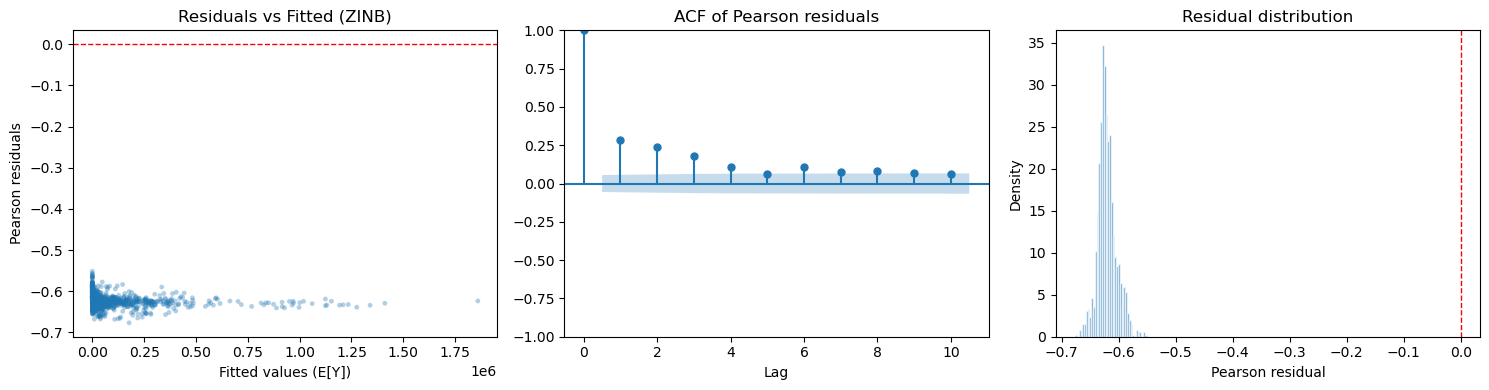

Pearson residual mean   : -0.6212
Pearson residual std    : 0.0167
Proportion of zeros in y: 0.377
Posterior mean psi      : 0.994
AP RR range: 0.900 to 3.981


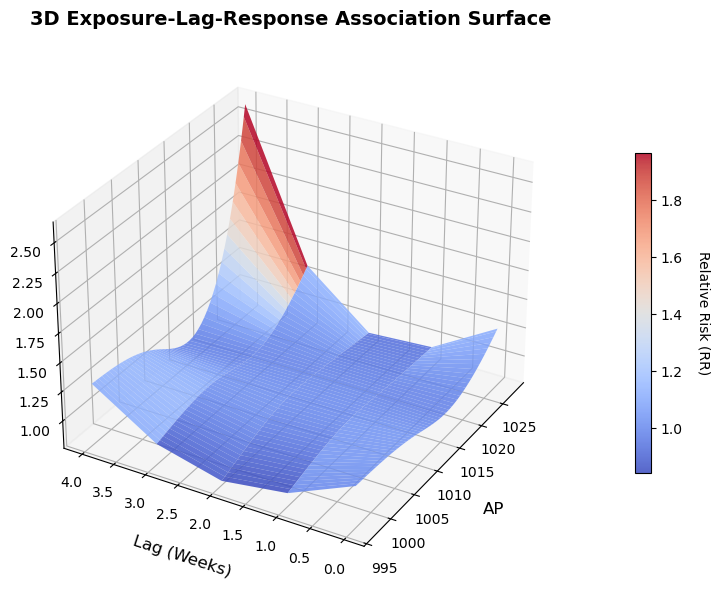

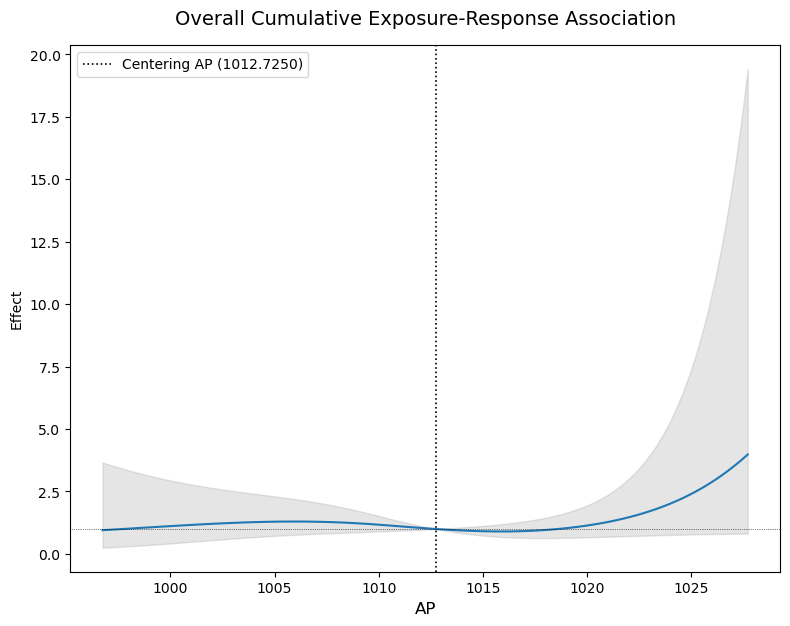

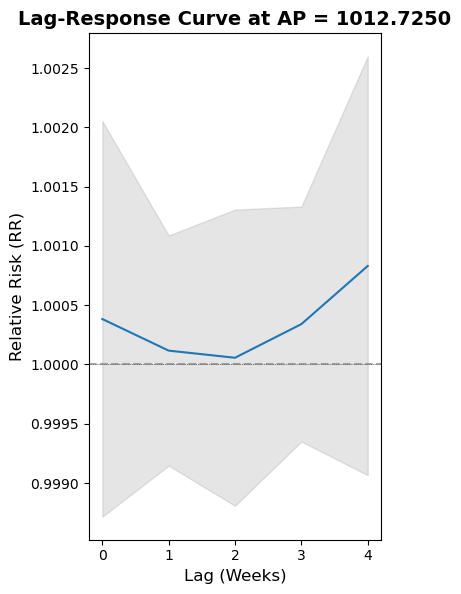

**============================== DPT (ZINB) ==============================**

============================== Hyperparameter tuning ==============================
=============== Tuning CrossBasis settings ===============
BIC for (2, 3, 2, 3): 10349.55
BIC for (2, 3, 2, 4): 10353.68
BIC for (2, 3, 3, 3): 10349.55
BIC for (2, 3, 3, 4): 10353.68
BIC for (2, 4, 2, 3): 10358.32
BIC for (2, 4, 2, 4): 10367.66
BIC for (2, 4, 3, 3): 10358.32
BIC for (2, 4, 3, 4): 10367.66
BIC for (3, 3, 2, 3): 10349.55
BIC for (3, 3, 2, 4): 10353.68
BIC for (3, 3, 3, 3): 10349.55
BIC for (3, 3, 3, 4): 10353.68
BIC for (3, 4, 2, 3): 10358.32
BIC for (3, 4, 2, 4): 10367.66
BIC for (3, 4, 3, 3): 10358.32
BIC for (3, 4, 3, 4): 10367.66
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10349.55)

=============== Tuning smoother degrees of freedom ===============
Degrees of freedom (8, 4, 5): BIC=9343.7799 | sum(EDF)=26.3665
Degrees of freedom (8, 4, 6): BIC=9329.2657 | sum(EDF)=26.6929
Degrees of freedom (8, 4, 7): BIC=9329.6427 | sum(EDF)=27.4268
Degrees of freedom (8, 5, 5): BIC=9343.7804 | sum

,alpha,AIC,BIC,GCV,EDF
KFold,"(5.011872336272722, 5.011872336272722, 125.892...",7962.502752,8181.259559,1.072017,42.648492



=============== Tuning Negative Binomial dispersion parameter ===============
Dispersion   1.5: Pearson ratio = 1.9219 | BIC = 8195.5225
Dispersion   2.0: Pearson ratio = 1.4821 | BIC = 8277.1376
Dispersion   3.0: Pearson ratio = 0.9428 | BIC = 8476.5910
Dispersion   4.0: Pearson ratio = 0.6830 | BIC = 8673.4522
Dispersion   5.0: Pearson ratio = 0.5255 | BIC = 8850.5702

Best dispersion parameter: 3.0 (Pearson ratio = 0.9428)

============================== Negative Binomial GLMGam ==============================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1205.97
Model Family:        NegativeBinomial   Df Model:                        41.03
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -4088.5
Date:  

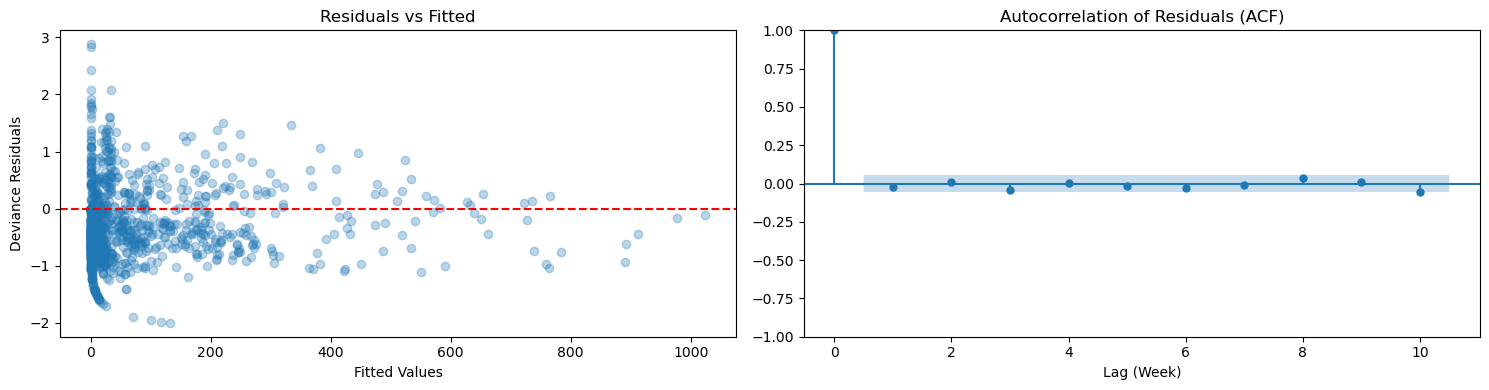

DPT RR range: 0.997 to 5.367


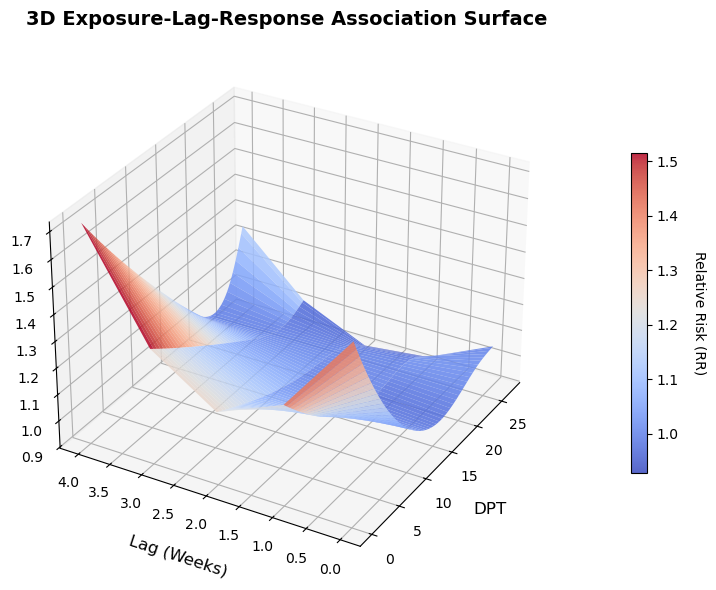

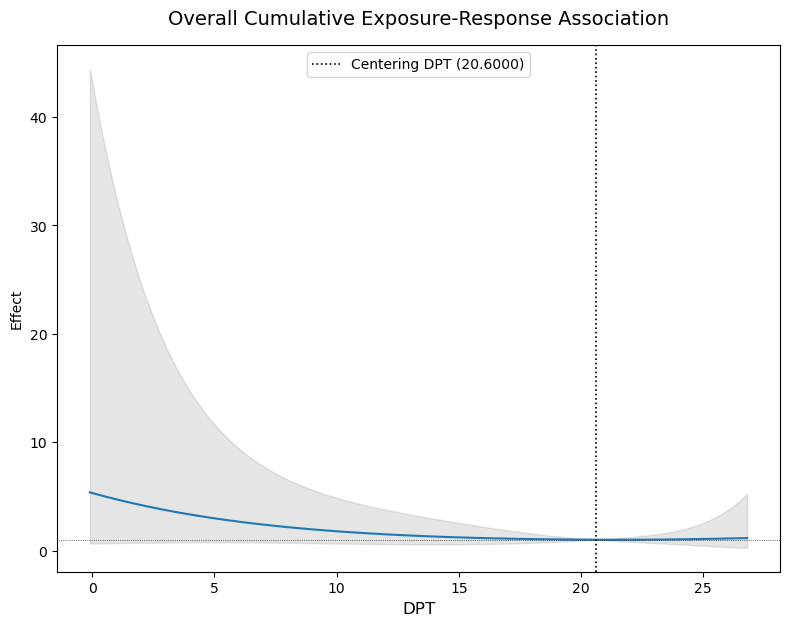

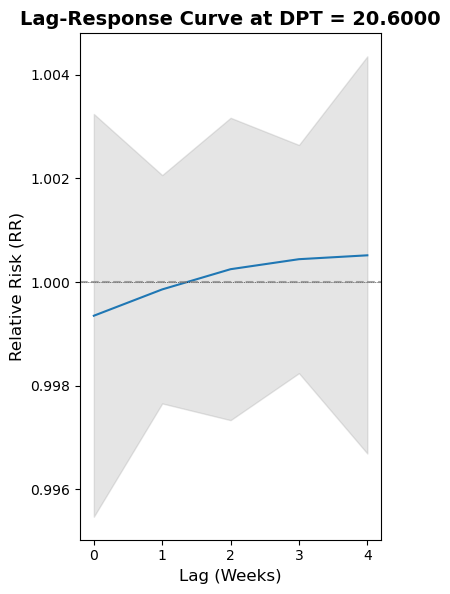


============================== Zero-Inflated Negative Binomial ==============================


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept_mu, beta, psi, alpha]


Output()

Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 172 seconds.


Output()

IN-SAMPLE metrics: not a forecast-performance estimate.


... (2 outputs left out)

,value
divergences,0.000000
max_r_hat,1.002084
min_bulk_ESS,3874.505705
min_tail_ESS,3813.167025


,Pearson_residual_ACF
1,0.157020
2,0.193975
3,0.131366
4,0.043053
5,0.015994
6,0.043762
7,-0.001715
8,0.051666
9,-0.030277
10,-0.004082


Computed; inspect Pareto-k diagnostics. This is not leave-future-out validation.
Computed from 6000 posterior samples and 1248 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -4162.79    96.27
p_loo       42.22        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)     1247   99.9%
   (0.70, 1]   (bad)         1    0.1%
    (1, Inf)   (very bad)    0    0.0%



,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta[DPT_basis_0],8086,4772,1.00,0.0043,0.0047
beta[DPT_basis_1],4039,4406,1.00,0.0044,0.0035
beta[DPT_basis_2],7771,5377,1.00,0.0038,0.0039
beta[DPT_basis_3],8868,4969,1.00,0.0076,0.0091
beta[DPT_basis_4],5221,4470,1.00,0.008,0.0071
beta[DPT_basis_5],7896,4600,1.00,0.0074,0.0082
beta[DPT_basis_6],8603,4890,1.00,0.005,0.0059
beta[DPT_basis_7],3874,4025,1.00,0.005,0.004
beta[DPT_basis_8],8438,4902,1.00,0.0041,0.0048
beta[pandemic_flag],6805,4442,1.00,0.0048,0.005


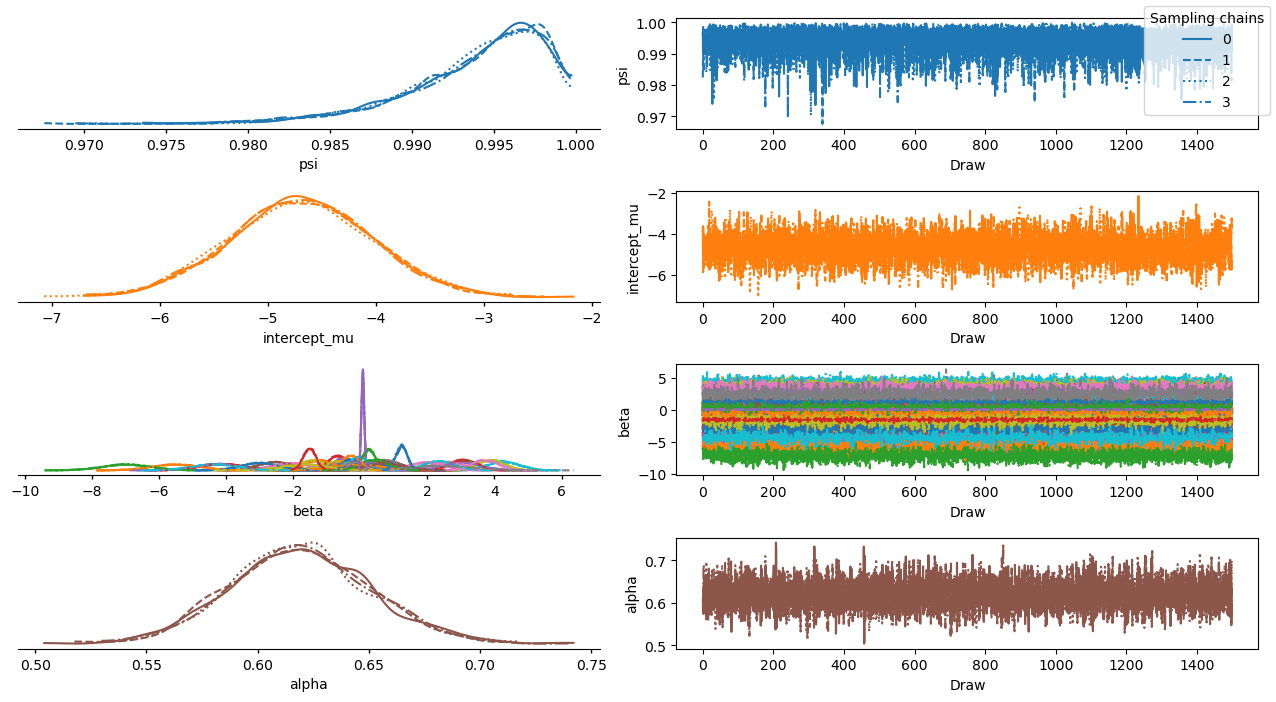


--- Residual diagnostics (ZINB) ---


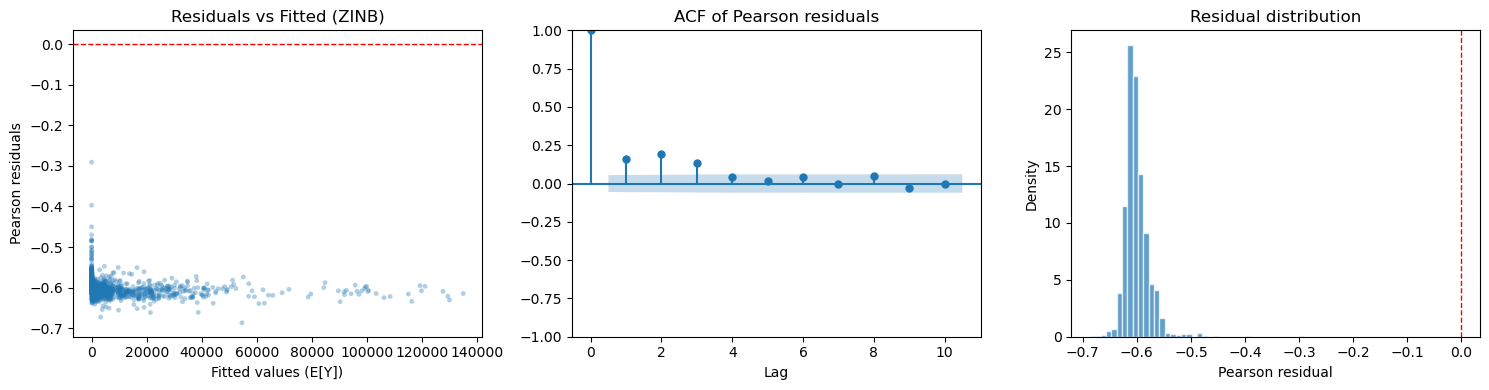

Pearson residual mean   : -0.6004
Pearson residual std    : 0.0241
Proportion of zeros in y: 0.377
Posterior mean psi      : 0.994
DPT RR range: 0.845 to 8.585


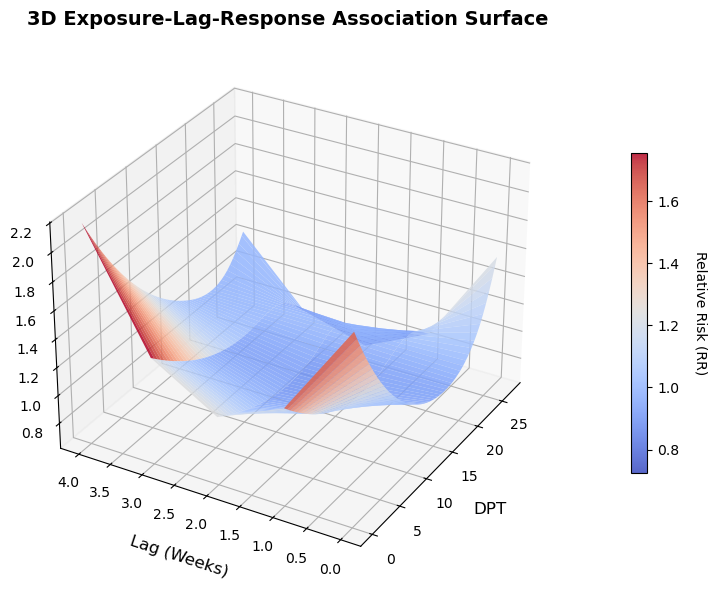

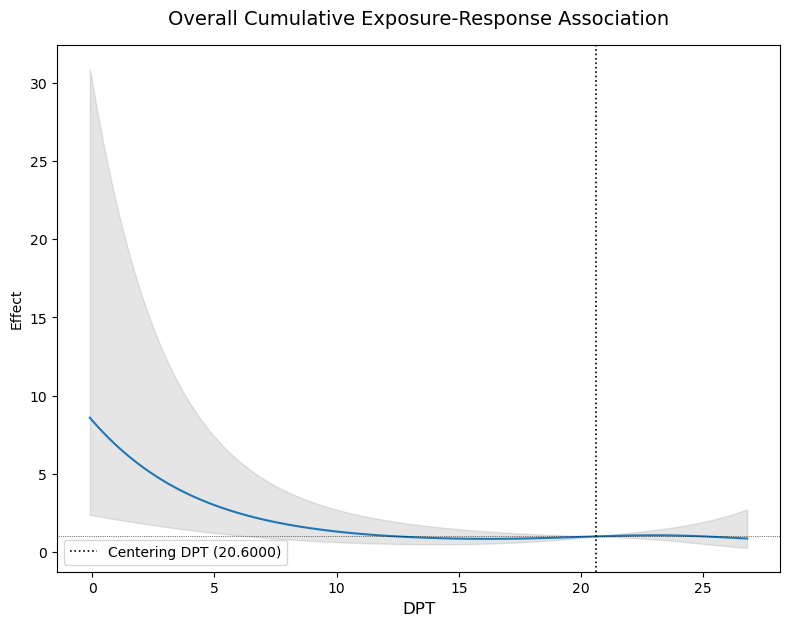

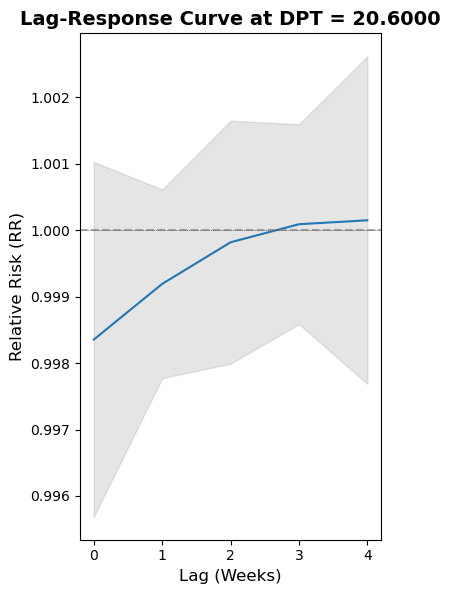

**============================== WS (ZINB) ==============================**

============================== Hyperparameter tuning ==============================
=============== Tuning CrossBasis settings ===============
BIC for (2, 3, 2, 3): 10450.81
BIC for (2, 3, 2, 4): 10467.91
BIC for (2, 3, 3, 3): 10450.81
BIC for (2, 3, 3, 4): 10467.91
BIC for (2, 4, 2, 3): 10467.15
BIC for (2, 4, 2, 4): 10490.19
BIC for (2, 4, 3, 3): 10467.15
BIC for (2, 4, 3, 4): 10490.19
BIC for (3, 3, 2, 3): 10450.81
BIC for (3, 3, 2, 4): 10467.91
BIC for (3, 3, 3, 3): 10450.81
BIC for (3, 3, 3, 4): 10467.91
BIC for (3, 4, 2, 3): 10467.15
BIC for (3, 4, 2, 4): 10490.19
BIC for (3, 4, 3, 3): 10467.15
BIC for (3, 4, 3, 4): 10490.19
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10450.81)

=============== Tuning smoother degrees of freedom ===============
Degrees of freedom (8, 4, 5): BIC=9366.9720 | sum(EDF)=26.0691
Degrees of freedom (8, 4, 6): BIC=9330.0584 | sum(EDF)=27.4670
Degrees of freedom (8, 4, 7): BIC=9327.8960 | sum(EDF)=28.3166
Degrees of freedom (8, 5, 5): BIC=9366.9720 | sum

,alpha,AIC,BIC,GCV,EDF
KFold,"(25.118864315095795, 630.957344480193, 630.957...",7977.197375,8211.433957,1.077406,45.666406



=============== Tuning Negative Binomial dispersion parameter ===============
Dispersion   1.5: Pearson ratio = 1.9170 | BIC = 8215.1165
Dispersion   2.0: Pearson ratio = 1.4261 | BIC = 8316.3581
Dispersion   3.0: Pearson ratio = 0.8758 | BIC = 8505.7833
Dispersion   4.0: Pearson ratio = 0.6241 | BIC = 8690.9914
Dispersion   5.0: Pearson ratio = 0.4827 | BIC = 8858.3747

Best dispersion parameter: 3.0 (Pearson ratio = 0.8758)

============================== Negative Binomial GLMGam ==============================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1204.27
Model Family:        NegativeBinomial   Df Model:                        42.73
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -4097.0
Date:  

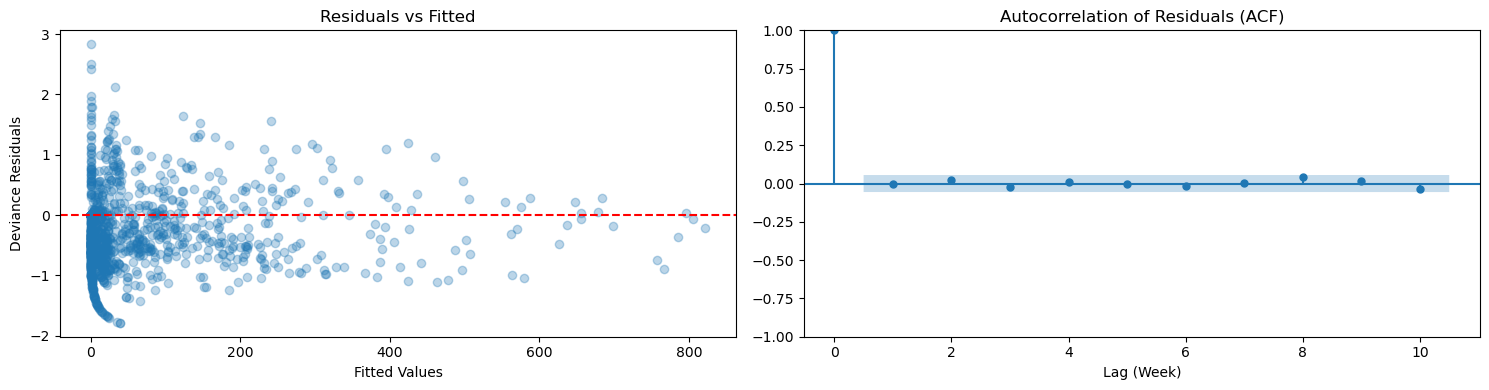

WS RR range: 0.409 to 1.040


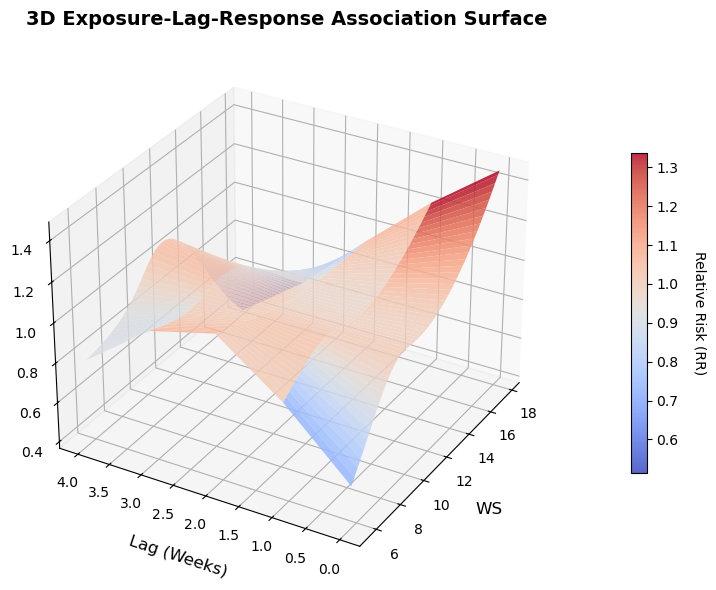

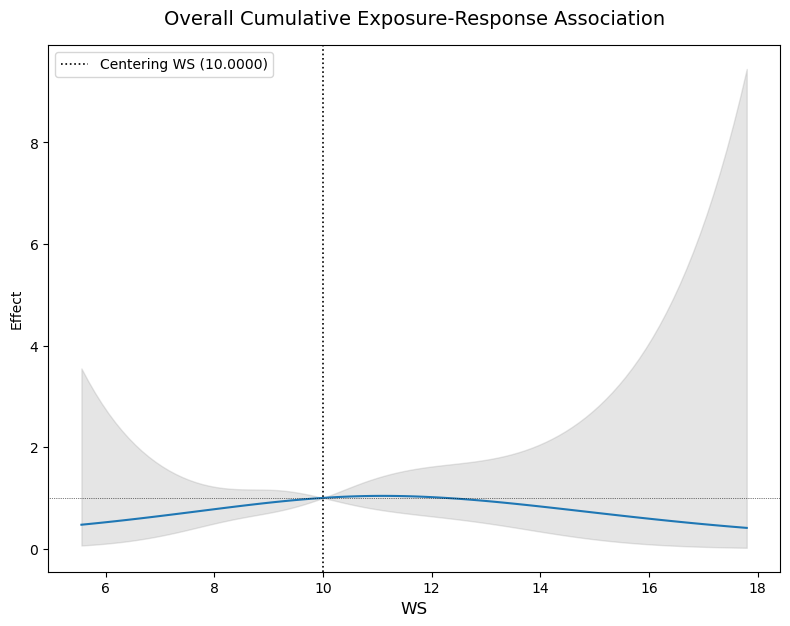

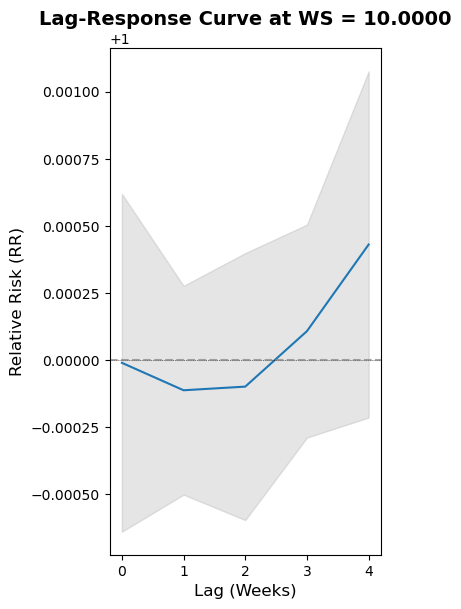


============================== Zero-Inflated Negative Binomial ==============================


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept_mu, beta, psi, alpha]


Output()

Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 207 seconds.


Output()

IN-SAMPLE metrics: not a forecast-performance estimate.


,in_sample_value
n_observations,1.248000e+03
MAE_predictive_median,7.127971e+04
RMSE_predictive_mean,5.040614e+05
mean_prediction_minus_observed,2.156291e+05
observed_zero_fraction,3.766026e-01
predicted_zero_fraction,1.592487e-02
zero_event_Brier_score,3.549137e-01
coverage_80,1.362179e-02
coverage_95,2.075321e-01
mean_interval_width_80,5.083170e+05


,value
divergences,0.000000
max_r_hat,1.002269
min_bulk_ESS,2913.822076
min_tail_ESS,3553.715629


,Pearson_residual_ACF
1,0.114232
2,0.093811
3,0.070187
4,0.027030
5,-0.001569
6,0.046028
7,0.066056
8,0.063134
9,0.040677
10,0.051001


Computed; inspect Pareto-k diagnostics. This is not leave-future-out validation.
Computed from 6000 posterior samples and 1248 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -4162.16    96.16
p_loo       44.53        -
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)     1248  100.0%
   (0.70, 1]   (bad)         0    0.0%
    (1, Inf)   (very bad)    0    0.0%



,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta[WS_basis_0],6611,4504,1.00,0.0036,0.0034
beta[WS_basis_1],6584,4955,1.00,0.0026,0.0025
beta[WS_basis_2],6991,4811,1.00,0.0028,0.0027
beta[WS_basis_3],7360,5066,1.00,0.0079,0.0078
beta[WS_basis_4],4022,4538,1.00,0.0085,0.006
beta[WS_basis_5],6798,5170,1.00,0.0071,0.007
beta[WS_basis_6],6925,5065,1.00,0.0062,0.0058
beta[WS_basis_7],4886,4700,1.00,0.0059,0.0049
beta[WS_basis_8],6600,5129,1.00,0.0055,0.0052
beta[pandemic_flag],4660,4686,1.00,0.0069,0.0057


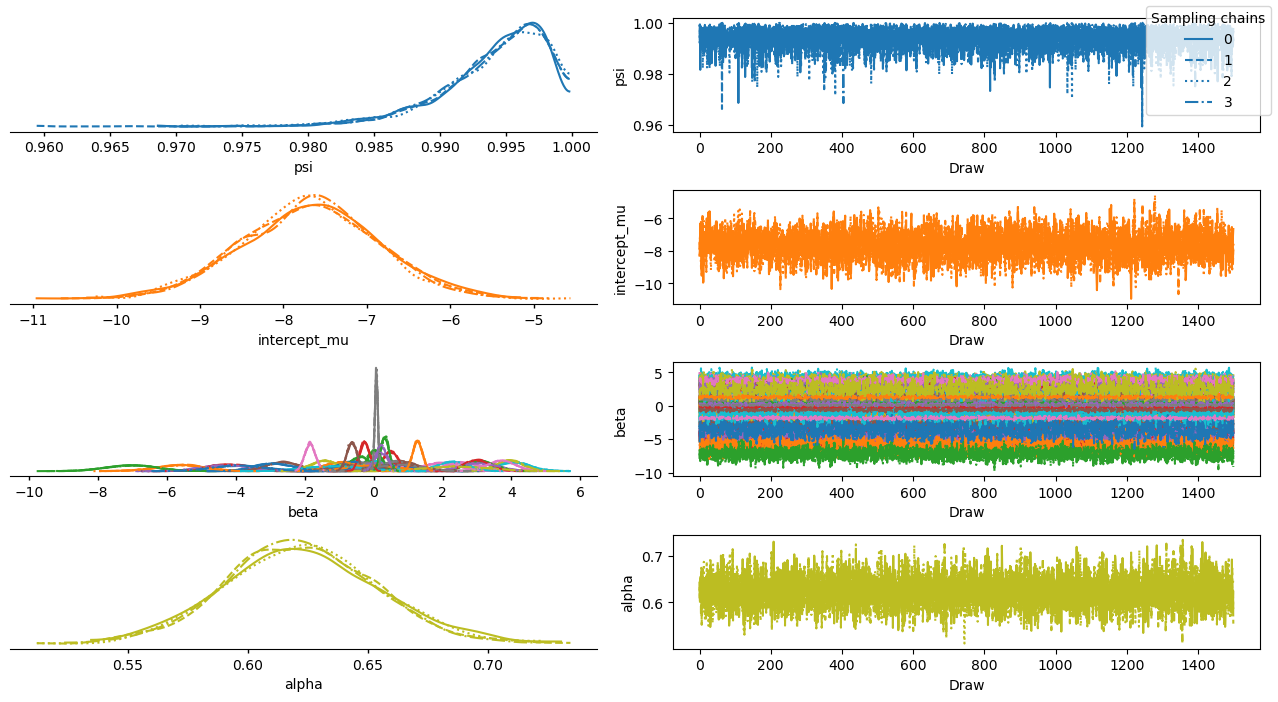


--- Residual diagnostics (ZINB) ---


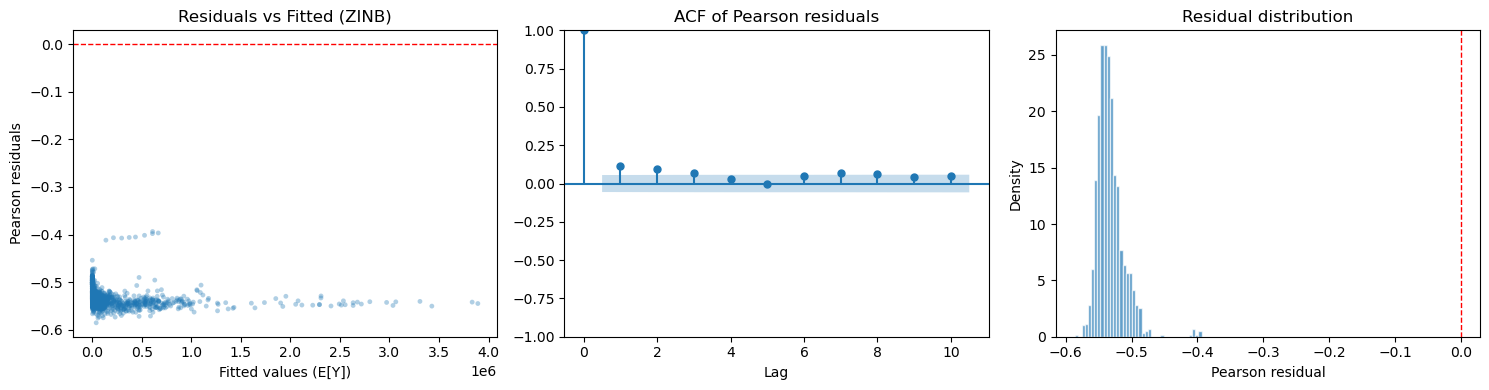

Pearson residual mean   : -0.5325
Pearson residual std    : 0.0210
Proportion of zeros in y: 0.377
Posterior mean psi      : 0.994
WS RR range: 0.652 to 1.324


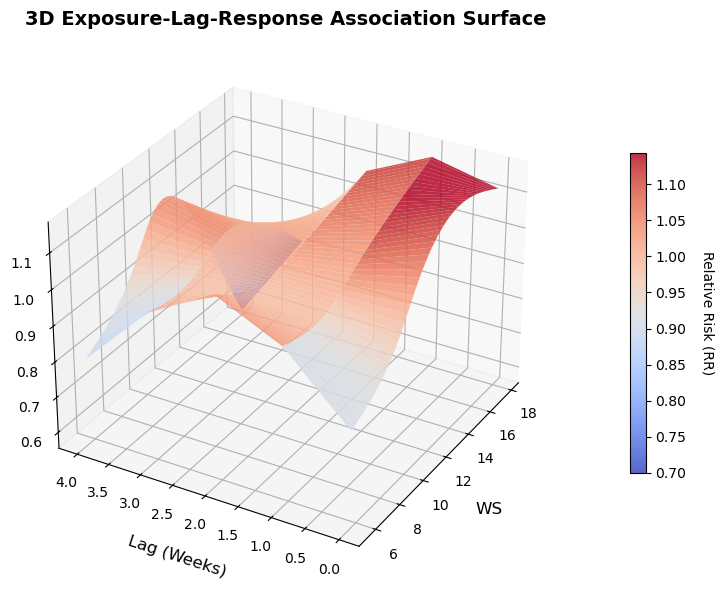

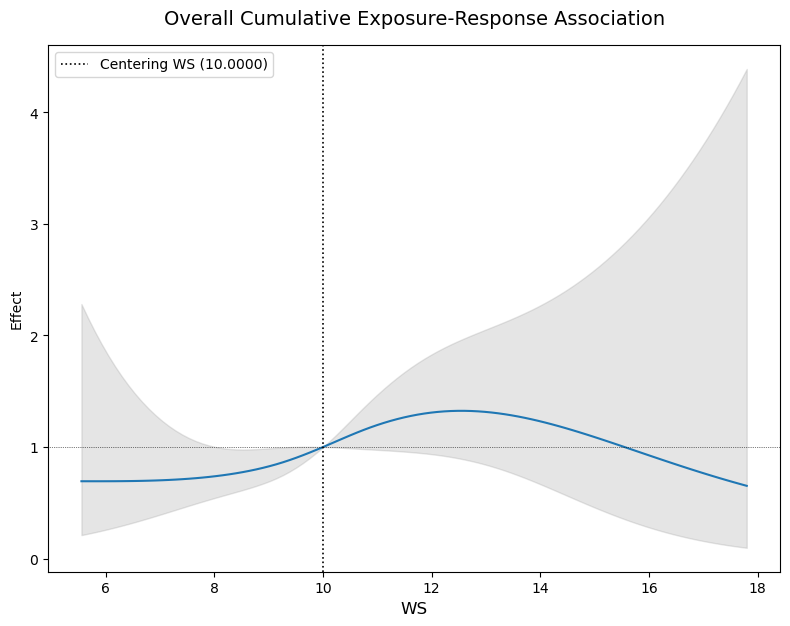

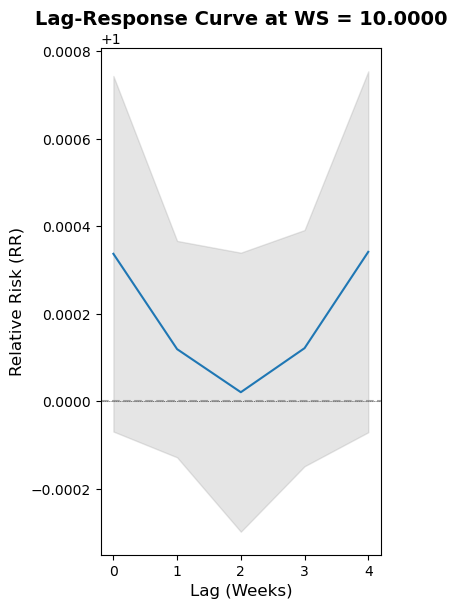

**============================== UV (ZINB) ==============================**

============================== Hyperparameter tuning ==============================
=============== Tuning CrossBasis settings ===============
BIC for (2, 3, 2, 3): 10390.31
BIC for (2, 3, 2, 4): 10407.32
BIC for (2, 3, 3, 3): 10390.31
BIC for (2, 3, 3, 4): 10407.32
BIC for (2, 4, 2, 3): 10401.67
BIC for (2, 4, 2, 4): 10425.26
BIC for (2, 4, 3, 3): 10401.67
BIC for (2, 4, 3, 4): 10425.26
BIC for (3, 3, 2, 3): 10390.31
BIC for (3, 3, 2, 4): 10407.32
BIC for (3, 3, 3, 3): 10390.31
BIC for (3, 3, 3, 4): 10407.32
BIC for (3, 4, 2, 3): 10401.67
BIC for (3, 4, 2, 4): 10425.26
BIC for (3, 4, 3, 3): 10401.67
BIC for (3, 4, 3, 4): 10425.26
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 10390.31)

=============== Tuning smoother degrees of freedom ===============
Degrees of freedom (8, 4, 5): BIC=9356.1532 | sum(EDF)=26.5444
Degrees of freedom (8, 4, 6): BIC=9333.8445 | sum(EDF)=27.4629
Degrees of freedom (8, 4, 7): BIC=9333.6279 | sum(EDF)=28.8044
Degrees of freedom (8, 5, 5): BIC=9356.1531 | sum

,alpha,AIC,BIC,GCV,EDF
KFold,"(630.957344480193, 1.0, 25.118864315095795)",7982.133226,8205.546848,1.073634,43.556378



=============== Tuning Negative Binomial dispersion parameter ===============
Dispersion   1.5: Pearson ratio = 1.1271 | BIC = 8225.5715
Dispersion   2.0: Pearson ratio = 0.9201 | BIC = 8309.0244
Dispersion   3.0: Pearson ratio = 0.7019 | BIC = 8510.5613
Dispersion   4.0: Pearson ratio = 0.5764 | BIC = 8702.8260
Dispersion   5.0: Pearson ratio = 0.4238 | BIC = 8873.9703

Best dispersion parameter: 2.0 (Pearson ratio = 0.9201)

============================== Negative Binomial GLMGam ==============================
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1248
Model:                         GLMGam   Df Residuals:                  1205.25
Model Family:        NegativeBinomial   Df Model:                        41.75
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -4002.1
Date:  

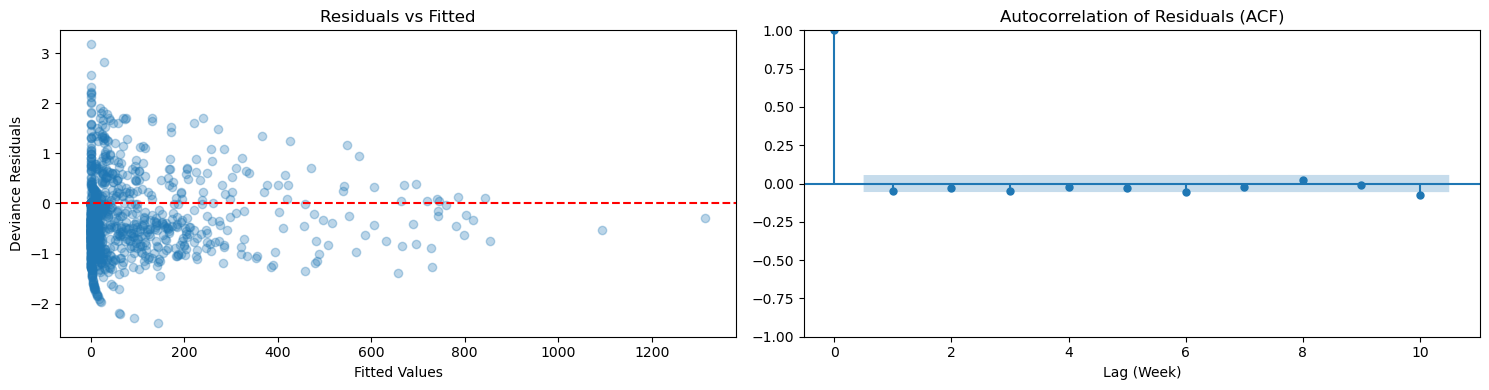

UV RR range: 0.999 to 8.027


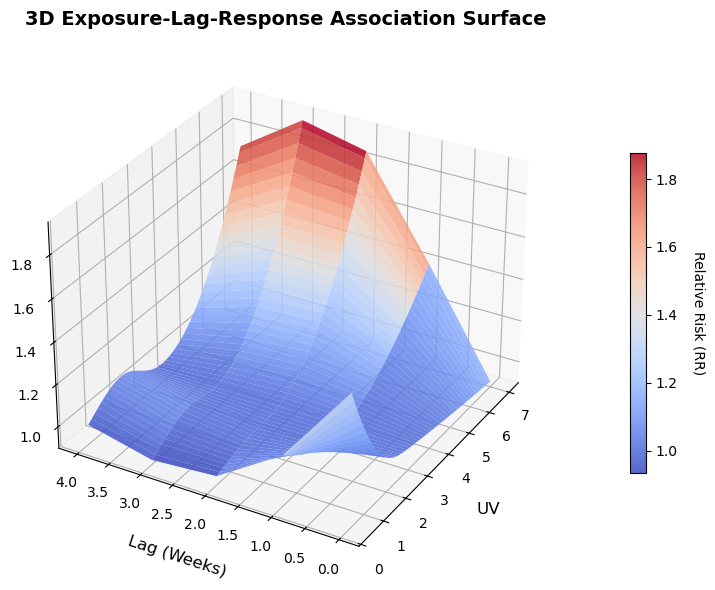

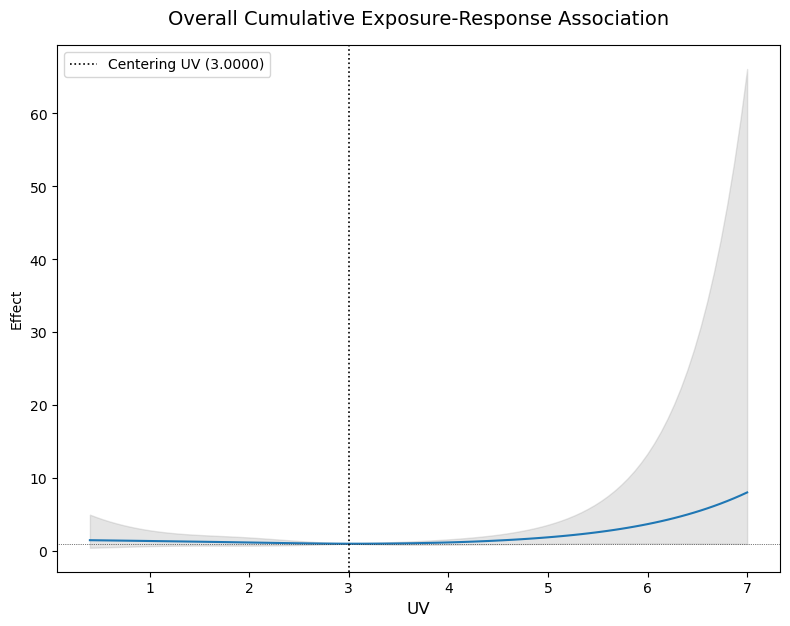

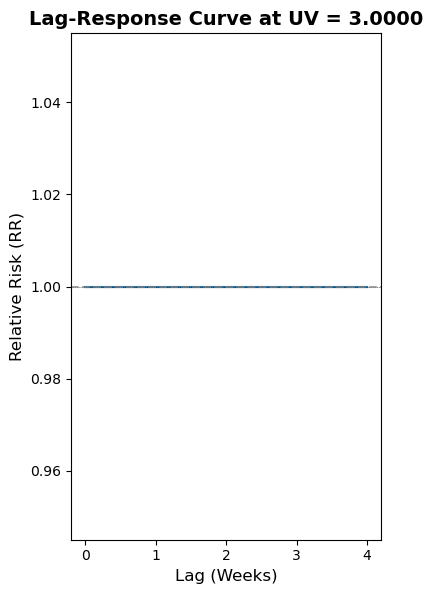


============================== Zero-Inflated Negative Binomial ==============================


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept_mu, beta, psi, alpha]


Output()

Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 192 seconds.


Output()

IN-SAMPLE metrics: not a forecast-performance estimate.


,in_sample_value
n_observations,1248.000000
MAE_predictive_median,44547.774038
RMSE_predictive_mean,288719.136392
mean_prediction_minus_observed,124729.051423
observed_zero_fraction,0.376603
predicted_zero_fraction,0.019405
zero_event_Brier_score,0.349232
coverage_80,0.019231
coverage_95,0.284455
mean_interval_width_80,305351.860897


,value
divergences,0.000000
max_r_hat,1.001885
min_bulk_ESS,3924.629757
min_tail_ESS,4097.100656


,Pearson_residual_ACF
1,0.082216
2,0.102881
3,0.090381
4,0.036692
5,0.011655
6,0.044508
7,0.011466
8,0.013671
9,0.007340
10,0.044123


Computed; inspect Pareto-k diagnostics. This is not leave-future-out validation.
Computed from 6000 posterior samples and 1248 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -4164.60    96.47
p_loo       46.35        -
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)     1248  100.0%
   (0.70, 1]   (bad)         0    0.0%
    (1, Inf)   (very bad)    0    0.0%



,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta[UV_basis_0],10070,4974,1.00,0.0032,0.0043
beta[UV_basis_1],5342,5034,1.00,0.0032,0.0025
beta[UV_basis_2],9496,5004,1.00,0.0028,0.0036
beta[UV_basis_3],8365,4682,1.00,0.0062,0.0073
beta[UV_basis_4],5139,4499,1.00,0.0064,0.005
beta[UV_basis_5],7298,5103,1.00,0.0057,0.0056
beta[UV_basis_6],7270,5083,1.00,0.0051,0.005
beta[UV_basis_7],4792,4756,1.00,0.0053,0.004
beta[UV_basis_8],7516,5332,1.00,0.0041,0.0041
beta[pandemic_flag],5841,4895,1.00,0.0061,0.0055


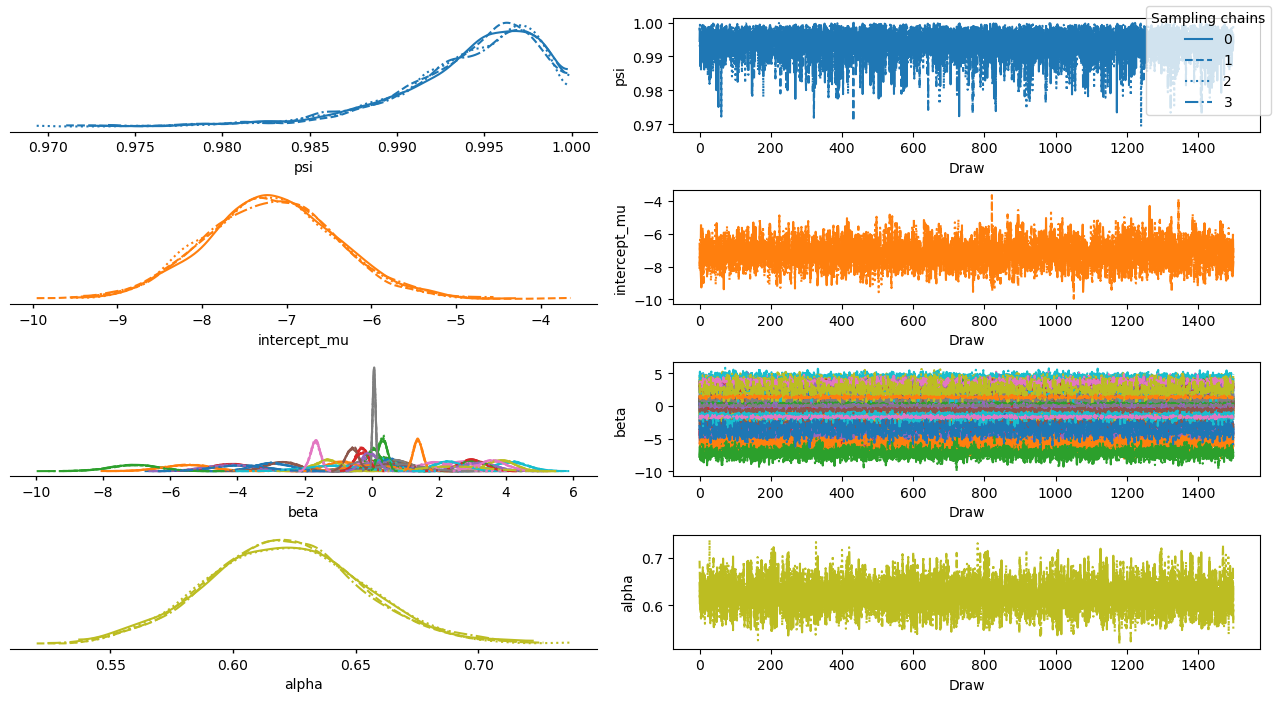


--- Residual diagnostics (ZINB) ---


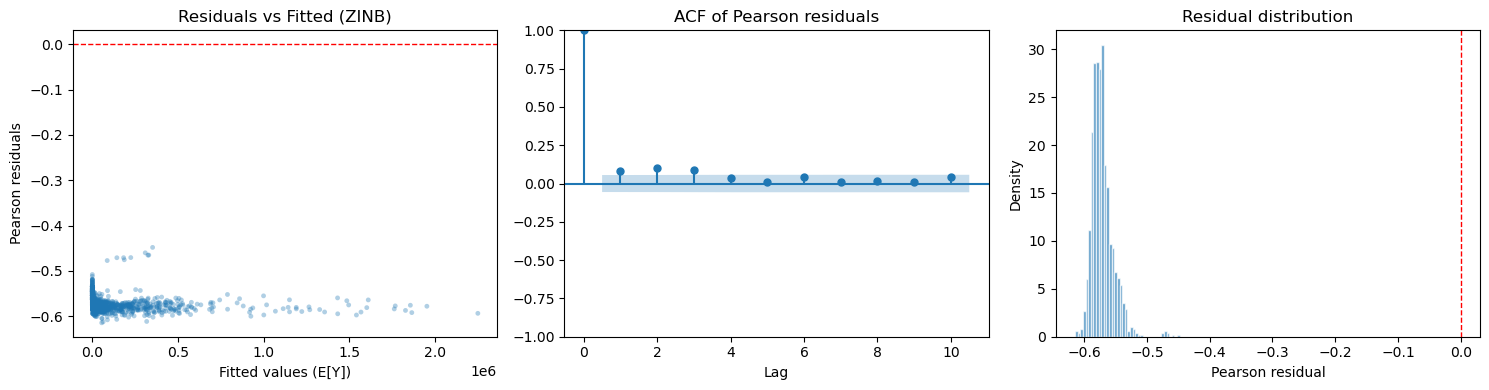

Pearson residual mean   : -0.5712
Pearson residual std    : 0.0178
Proportion of zeros in y: 0.377
Posterior mean psi      : 0.994
UV RR range: 1.000 to 4.289


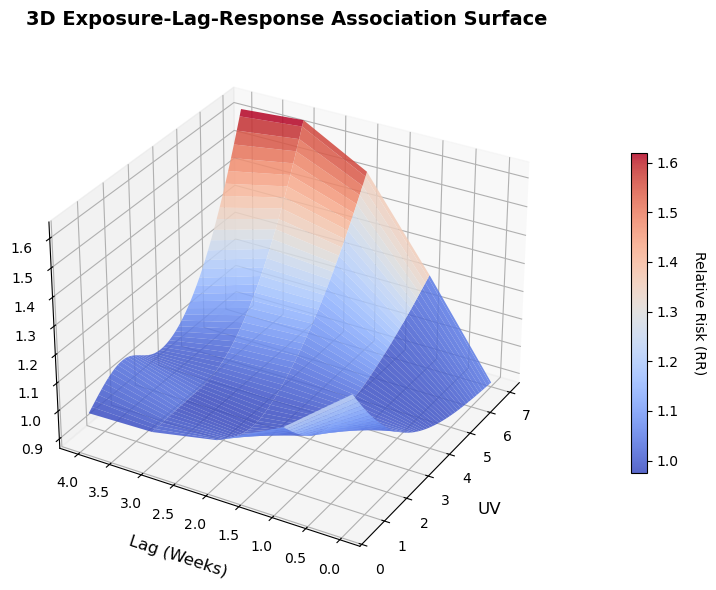

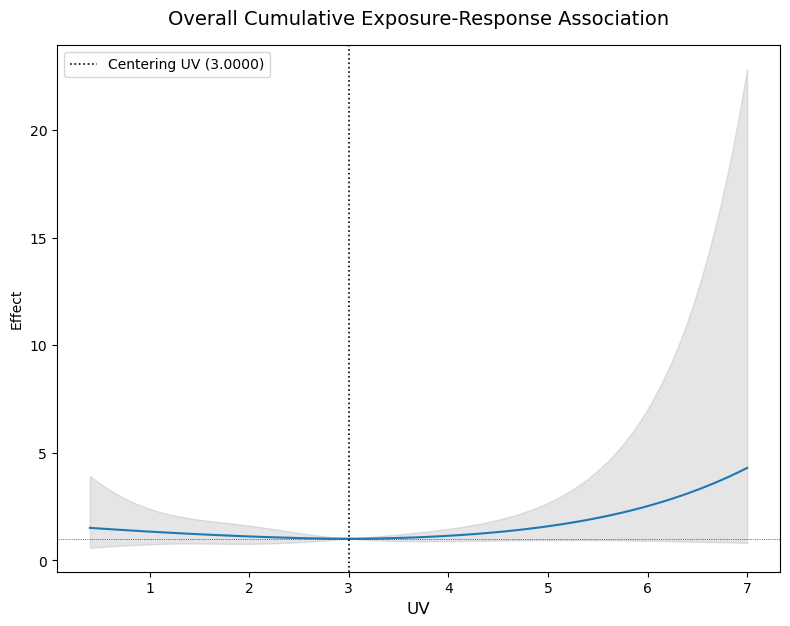

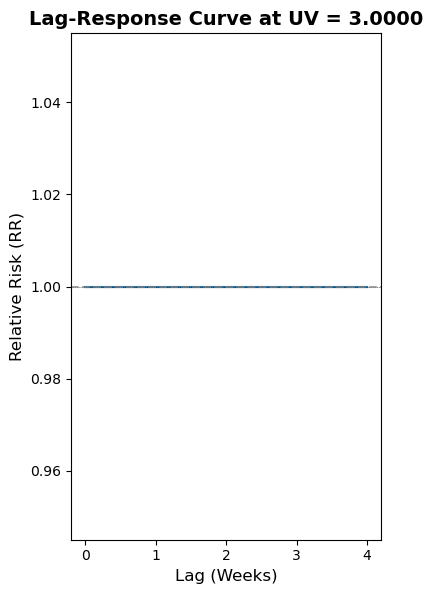

In [ ]:
# All meterological variables
tar_var = "H1"
for exp in mete_col:
    exp_col_list = [exp]

    display(Markdown(f"**{'='*30} {exp} (ZINB) {'='*30}**"))

    idata, pred, model_data, cb_list, colnames, nb_result, resid, report = DLNM_ZINB(
        df, max_lag=4,
        tar_var=tar_var, exp_col_list=exp_col_list, linear_predictors_list=linear_predictors_list,
        bs_name_lst=bs_name_lst, ccs_name_lst=ccs_name_lst,
        cb_grid=cb_grid, smoother_grid=smoother_grid, disp_grid=disp_grid, criterion_lst=[],
        # PyMC controls – reduce draws/tune for a quick test
        draws=1500, tune=1500, target_accept=0.95, chains=4, cores=4, psi_prior="logistic", prior_sigma=1.0
    )


---